# Identifying U.S. Economic and Financial Market Regimes Using Machine Learning

## Capstone Project Overview

This project explores how machine learning can be used to identify U.S. economic and financial market regimes, classify recessionary conditions, and predict S&P 500 returns using historical macroeconomic and financial indicators from 1960 to June 2026.

The analysis is divided into two parts:

### Part A [Sections 1-20]: Economic Regime Identification and Recession Classification

- **Unsupervised Learning:** Apply Principal Component Analysis (PCA) and compare K-Means, Gaussian Mixture Model (GMM), and DBSCAN to identify patterns in economic and financial conditions.
- **Historical Analysis:** Examine how identified clusters relate to historical periods of inflation, economic expansion, recovery, and recession.
- **Supervised Learning:** Evaluate Logistic Regression, Decision Tree, Random Forest, and KNN using independently defined NBER recession labels.

### Part B [Sections 21-22]: S&P 500 Return Prediction

- Apply Ridge Regression to predict the following month's S&P 500 return using economic and financial indicators.
- Use chronological cross-validation to tune the regularization parameter.
- Evaluate forecasting performance using Mean Absolute Error (MAE) and R², with a historical mean baseline for comparison.


## 1. Part A: Import Libraries

Import the libraries needed for data preparation, visualization, and modeling.

In [2097]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyRegressor

from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV

from sklearn.metrics import (
    silhouette_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    make_scorer,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

### Data Sources

Historical data was downloaded from FRED (Federal Reserve Bank of St. Louis) and Multpl. FRED provided the macroeconomic indicators, while Multpl provided the S&P 500 Index and 10-Year Treasury Yield. The datasets were downloaded as CSV files and prepared for monthly analysis.

In [2098]:
# Folder containing the data files
folder = "data"

# File names and the variable name used in the analysis
files = {
    "SP500": "SP500.csv",
    "CPI": "CPI.csv",
    "Unemployment_Rate": "UNRATE.csv",
    "Federal_Funds_Rate": "FEDFUNDS.csv",
    "Economic_Policy_Uncertainty_Index": "USEPUINDXD.csv",
    "Equity_Market_Volatility_Tracker": "EMVOVERALLEMV.csv",
    "Treasury_Yield_2Y": "GS2.csv",
    "Treasury_Yield_10Y": "GS10.csv",
    "GDP": "GDP.csv",
    "REAL_GDP_PER_CAPITA": "Real_GDP_Per_Capita.csv",
    "MV_Gross_Federal_Debt": "Federal_Debt.csv",
    "Real_Disposable_Personal_Income": "Disposable_Income.csv"
}

### 2. Load the Data

Load each CSV file, standardize the date and value columns, and store each dataset in a dictionary.

In [2099]:
datasets = {}

#Read CSV file
for name, file in files.items():

    df = pd.read_csv(os.path.join(folder, file))

    #Keep first two columns and rename
    df = df.iloc[:, :2].copy()
    df.columns = ["Date", name]

    #Convert Date column to datetime
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    #Clean numeric values
    df[name] = (
        df[name].astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )

    #Convert cleaned values to numeric
    df[name] = pd.to_numeric(df[name], errors="coerce") 

    #Remove invalid dates and sort chronologically
    df = df.dropna(subset=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    #Store cleaned dataset
    datasets[name] = df  

In [2100]:
for name, df in datasets.items():
    print(name)
    print("Rows:", len(df))
    print("Missing Values:", df[name].isnull().sum())
    print()

SP500
Rows: 1522
Missing Values: 0

CPI
Rows: 956
Missing Values: 1

Unemployment_Rate
Rows: 944
Missing Values: 1

Federal_Funds_Rate
Rows: 866
Missing Values: 0

Economic_Policy_Uncertainty_Index
Rows: 15245
Missing Values: 0

Equity_Market_Volatility_Tracker
Rows: 500
Missing Values: 0

Treasury_Yield_2Y
Rows: 603
Missing Values: 0

Treasury_Yield_10Y
Rows: 922
Missing Values: 0

GDP
Rows: 318
Missing Values: 0

REAL_GDP_PER_CAPITA
Rows: 318
Missing Values: 0

MV_Gross_Federal_Debt
Rows: 1016
Missing Values: 0

Real_Disposable_Personal_Income
Rows: 811
Missing Values: 0



### 3. Align Data Frequencies

The datasets have different reporting frequencies. The daily uncertainty index was converted to monthly averages, and the remaining series were aligned to a common monthly timeline. GDP and real GDP per capita required additional handling because they are reported quarterly.

In [2101]:
# Convert daily Economic Policy Uncertainty data to monthly average
df = datasets["Economic_Policy_Uncertainty_Index"].copy()

# Convert daily dates to monthly dates
df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# Calculate monthly average
df = df.groupby("Date", as_index=False)["Economic_Policy_Uncertainty_Index"].mean()

# Save updated dataset
datasets["Economic_Policy_Uncertainty_Index"] = df

In [2102]:
# Variables that are already reported monthly
monthly_variables = [
    "SP500",
    "CPI",
    "Unemployment_Rate",
    "Federal_Funds_Rate",
    "Equity_Market_Volatility_Tracker",
    "Treasury_Yield_2Y",
    "Treasury_Yield_10Y",
    "MV_Gross_Federal_Debt",
    "Real_Disposable_Personal_Income"
]

for variable in monthly_variables:
    
    df = datasets[variable].copy()
    
    # Use the first day of each month as the common date
    df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp() 
    
    # Keep one value if a month appears more than once
    df = df.groupby("Date", as_index=False)[variable].last()
    
    datasets[variable] = df

### Quarterly Data

GDP and real GDP per capita are reported quarterly. Their dates are aligned with the monthly dataset before merging.

In [2103]:
quarterly_variables = [
    "GDP",
    "REAL_GDP_PER_CAPITA"
]

for variable in quarterly_variables:
    
    df = datasets[variable].copy()
    
    # Standardize quarterly dates to month-start
    df["Date"] = df["Date"].dt.to_period("M").dt.to_timestamp() 
    
    datasets[variable] = df

### 4. Combine the Datasets

Create a monthly date range and merge all indicators using the Date column.

In [2104]:
# Find earliest and latest dates
start_date = min(df["Date"].min() for df in datasets.values())
end_date = max(df["Date"].max() for df in datasets.values())

# Create monthly date range
master = pd.DataFrame()
master["Date"] = pd.date_range(start_date, end_date, freq="MS")

# Merge all datasets
for name, df in datasets.items():
    master = pd.merge(master, df, on="Date", how="left")

# View merged dataset
master.head()

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Economic_Policy_Uncertainty_Index,Equity_Market_Volatility_Tracker,Treasury_Yield_2Y,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
0,1900-01-01,6.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1900-02-01,6.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1900-03-01,6.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1900-04-01,6.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1900-05-01,6.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Forward Filling Quarterly Data

GDP data is available once every three months. After merging it with the monthly
calendar, the two months between quarterly observations are blank. Forward filling is used to carry the quarterly value into these two months.

In [2105]:
# Convert quarterly GDP data to monthly
master["GDP"] = master["GDP"].ffill(limit=2)

master["REAL_GDP_PER_CAPITA"] = master["REAL_GDP_PER_CAPITA"].ffill(limit=2)

In [2106]:
# Calculate missing values
missing_count = master.isnull().sum()
missing_percent = master.isnull().mean() * 100

# Create missing values summary
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

# Sort by highest missing percentage
missing_summary = missing_summary.sort_values("Missing_Percent", ascending=False)

# Display results
missing_summary

,Missing_Count,Missing_Percent
Equity_Market_Volatility_Tracker,1021,67.126890
Economic_Policy_Uncertainty_Index,1020,67.061144
Treasury_Yield_2Y,918,60.355030
Real_Disposable_Personal_Income,710,46.679816
Federal_Funds_Rate,655,43.063774
Treasury_Yield_10Y,600,39.447732
Unemployment_Rate,578,38.001315
GDP,567,37.278107
REAL_GDP_PER_CAPITA,567,37.278107
CPI,566,37.212360


In [2107]:
coverage = []

# Check date coverage for each variable
for name in master.columns[1:]:

    df = master.dropna(subset=[name])

    coverage.append({
        "Variable": name,
        "First_Date": df["Date"].min(),
        "Last_Date": df["Date"].max(),
        "Observations": len(df),
        "Coverage_Percent": round(len(df) / len(master) * 100, 2)
    })

coverage_df = pd.DataFrame(coverage) # Create summary table

coverage_df = coverage_df.sort_values("First_Date") # Sort by earliest date

coverage_df

,Variable,First_Date,Last_Date,Observations,Coverage_Percent
0,SP500,1900-01-01,2026-09-01,1521,100.00
10,MV_Gross_Federal_Debt,1942-01-01,2026-08-01,1016,66.80
1,CPI,1947-01-01,2026-08-01,955,62.79
8,GDP,1947-01-01,2026-06-01,954,62.72
9,REAL_GDP_PER_CAPITA,1947-01-01,2026-06-01,954,62.72
2,Unemployment_Rate,1948-01-01,2026-08-01,943,62.00
7,Treasury_Yield_10Y,1950-01-01,2026-09-01,921,60.55
3,Federal_Funds_Rate,1954-07-01,2026-08-01,866,56.94
11,Real_Disposable_Personal_Income,1959-01-01,2026-07-01,811,53.32
6,Treasury_Yield_2Y,1976-06-01,2026-08-01,603,39.64


### 5. Select the Final Study Period and Variables

January 1959 was selected as the starting point to include a longer history of economic cycles. The 2-Year Treasury Yield, Economic Policy Uncertainty Index, and Equity Market Volatility Tracker were excluded because their shorter coverage would require starting the analysis around 1985. This leaves nine core indicators, although some information from the excluded variables will be lost. The remaining nine indicators cover stock markets, interest rates, inflation, employment, economic growth, and federal debt.

### Selected Economic and Financial Indicators

The nine core economic and financial indicators used in the analysis are:

- **Stock Market:** S&P 500
- **Interest Rates:** Federal Funds Rate, 10-Year Treasury Yield
- **Inflation:** Consumer Price Index (CPI)
- **Employment:** Unemployment Rate
- **Economic Growth:** GDP, Real GDP per Capita, Real Disposable Personal Income
- **Federal Debt:** Gross Federal Debt

In [2108]:
# Selected period
final_data = master[
    (master["Date"] >= "1959-01-01") &
    (master["Date"] <= "2026-06-01")
].copy()

# Remove variables with limited historical coverage
columns_to_drop = [
    "Treasury_Yield_2Y",
    "Economic_Policy_Uncertainty_Index",
    "Equity_Market_Volatility_Tracker"
]

final_data = final_data.drop(columns=columns_to_drop)
final_data = final_data.reset_index(drop=True)
final_data.head()

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
0,1959-01-01,55.62,29.01,6.0,2.48,4.02,510.330,19041.0,273.7,13186.0
1,1959-02-01,54.77,29.00,5.9,2.43,3.96,510.330,19041.0,274.3,13209.0
2,1959-03-01,56.16,28.97,5.6,2.80,3.99,510.330,19041.0,270.0,13267.0
3,1959-04-01,57.10,28.98,5.2,2.96,4.12,522.653,19395.0,271.9,13336.0
4,1959-05-01,57.96,29.04,5.1,2.90,4.31,522.653,19395.0,272.3,13392.0


## 6. Check and Handle Missing Values

After selecting the final time period, the data was checked for missing values. Only one observation was missing in CPI and the Unemployment Rate. Linear interpolation is used to estimate the missing values.


In [2109]:
print("Shape:", final_data.shape)
print("Start date:", final_data["Date"].min())
print("End date:", final_data["Date"].max())

Shape: (810, 10)
Start date: 1959-01-01 00:00:00
End date: 2026-06-01 00:00:00


In [2110]:
final_data.isna().sum()

Date                               0
SP500                              0
CPI                                1
Unemployment_Rate                  1
Federal_Funds_Rate                 0
Treasury_Yield_10Y                 0
GDP                                0
REAL_GDP_PER_CAPITA                0
MV_Gross_Federal_Debt              0
Real_Disposable_Personal_Income    0
dtype: int64

In [2111]:
missing_final = pd.DataFrame({
    "Missing_Count": final_data.isna().sum(),
    "Missing_Percent": final_data.isna().mean() * 100
})

missing_final

,Missing_Count,Missing_Percent
Date,0,0.000000
SP500,0,0.000000
CPI,1,0.123457
Unemployment_Rate,1,0.123457
Federal_Funds_Rate,0,0.000000
Treasury_Yield_10Y,0,0.000000
GDP,0,0.000000
REAL_GDP_PER_CAPITA,0,0.000000
MV_Gross_Federal_Debt,0,0.000000
Real_Disposable_Personal_Income,0,0.000000


In [2112]:
final_data[
    final_data[["CPI", "Unemployment_Rate"]].isnull().any(axis=1)
]

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
801,2025-10-01,6735.69,NaN,NaN,4.09,4.06,31422.526,70249.0,36379.9,52684.0


In [2113]:
# Fill isolated missing values between valid monthly observations
final_data["CPI"] = final_data["CPI"].interpolate()
final_data["Unemployment_Rate"] = final_data["Unemployment_Rate"].interpolate()

In [2114]:
final_data.loc[
    final_data["Date"].between("2025-09-01", "2025-11-01")
]

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
800,2025-09-01,6584.02,324.245,4.40,4.22,4.12,31098.027,70218.0,35877.2,52865.0
801,2025-10-01,6735.69,324.654,4.45,4.09,4.06,31422.526,70249.0,36379.9,52684.0
802,2025-11-01,6740.89,325.063,4.50,3.88,4.09,31422.526,70249.0,36778.7,52667.0


In [2115]:
print("Rows:", len(final_data))
print("Start:", final_data["Date"].min())
print("End:", final_data["Date"].max())
print("Duplicate dates:", final_data["Date"].duplicated().sum())
print("Total missing values:", final_data.isna().sum().sum())

Rows: 810
Start: 1959-01-01 00:00:00
End: 2026-06-01 00:00:00
Duplicate dates: 0
Total missing values: 0


In [2116]:
final_data.head()

,Date,SP500,CPI,Unemployment_Rate,Federal_Funds_Rate,Treasury_Yield_10Y,GDP,REAL_GDP_PER_CAPITA,MV_Gross_Federal_Debt,Real_Disposable_Personal_Income
0,1959-01-01,55.62,29.01,6.0,2.48,4.02,510.330,19041.0,273.7,13186.0
1,1959-02-01,54.77,29.00,5.9,2.43,3.96,510.330,19041.0,274.3,13209.0
2,1959-03-01,56.16,28.97,5.6,2.80,3.99,510.330,19041.0,270.0,13267.0
3,1959-04-01,57.10,28.98,5.2,2.96,4.12,522.653,19395.0,271.9,13336.0
4,1959-05-01,57.96,29.04,5.1,2.90,4.31,522.653,19395.0,272.3,13392.0


## 7. Exploratory Data Analysis

Summary statistics, historical trends, and correlations were reviewed before creating the modeling features.

In [2117]:
final_data.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Date,810,1992-09-15 09:30:40,1959-01-01 00:00:00,1975-11-08 12:00:00,1992-09-16 00:00:00,2009-07-24 06:00:00,2026-06-01 00:00:00,NaN
SP500,810.0,1079.435642,53.73,101.35,418.205,1354.275,7450.03,1445.864328
CPI,810.0,143.03134,28.97,55.375,141.4,217.22525,333.979,87.17052
Unemployment_Rate,810.0,5.845494,3.4,4.6,5.6,6.9,14.8,1.683353
Federal_Funds_Rate,810.0,4.759926,0.05,2.0125,4.62,6.3925,19.1,3.582451
Treasury_Yield_10Y,810.0,5.735926,0.62,3.89,5.16,7.4575,15.32,2.888687
GDP,810.0,9243.912856,510.33,1761.831,6623.722,14764.61,32486.066,8389.812283
REAL_GDP_PER_CAPITA,810.0,42305.685185,19041.0,28935.0,40714.0,54945.0,70809.0,14682.054135
MV_Gross_Federal_Debt,810.0,8105.409012,269.9,557.6,4328.9,12262.1,37338.4,9861.12239
Real_Disposable_Personal_Income,810.0,30947.77284,13186.0,21396.5,29440.0,40069.25,61793.0,11433.663635


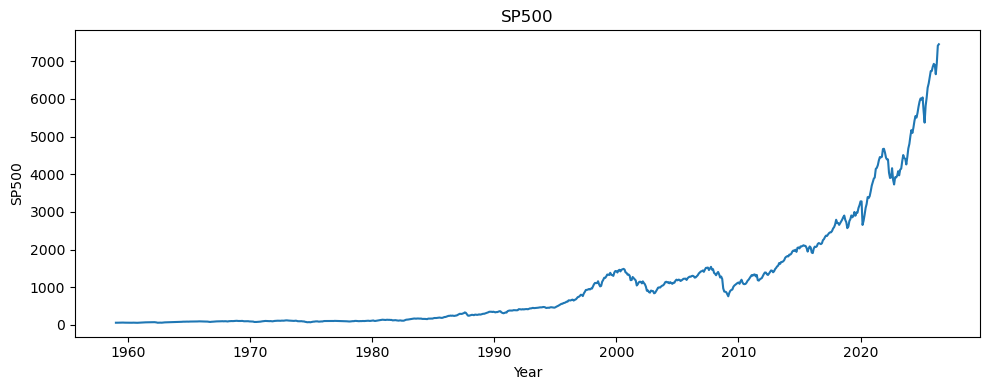

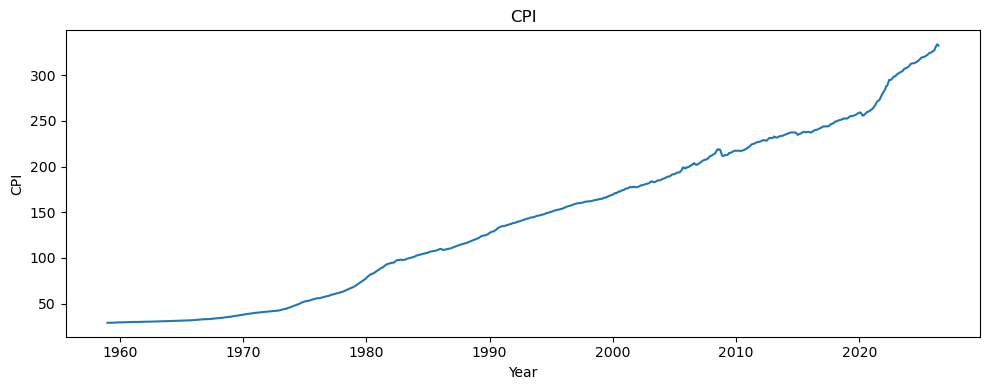

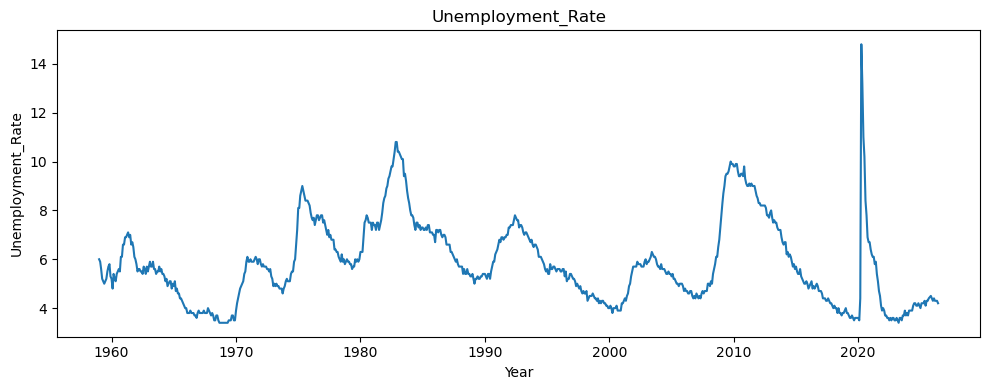

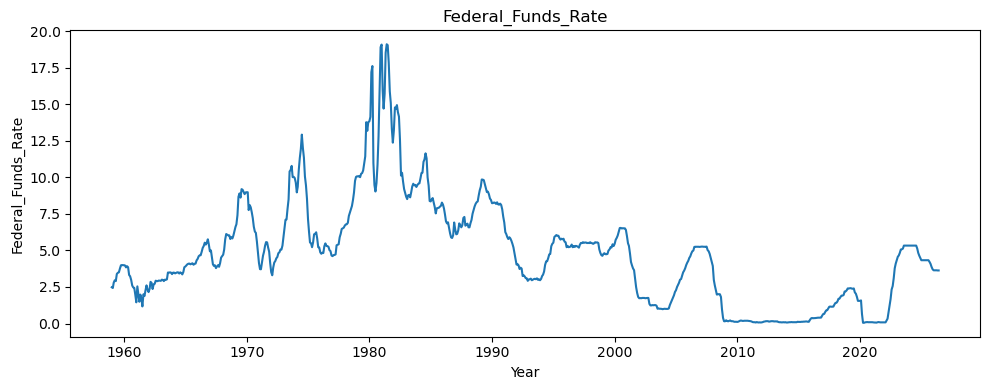

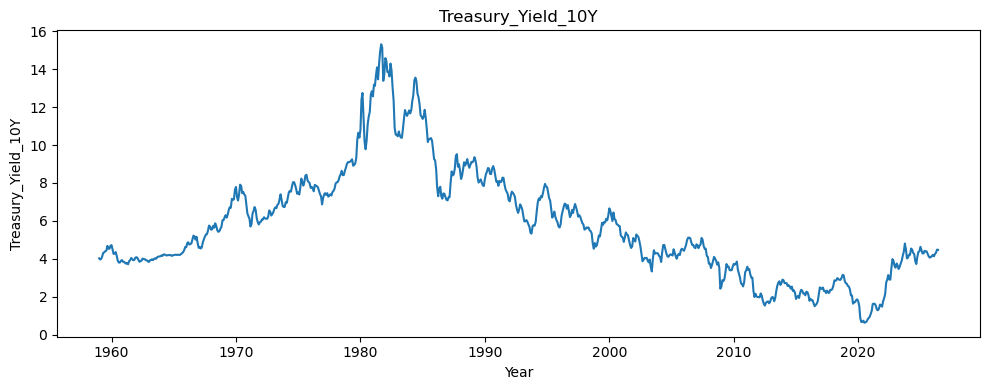

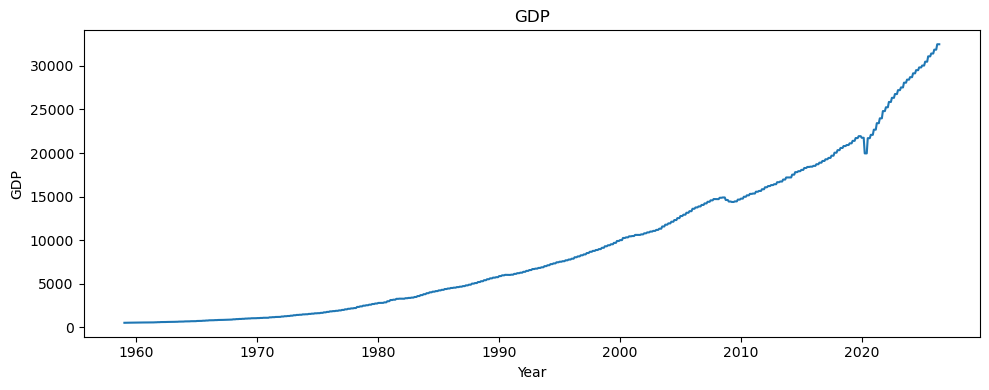

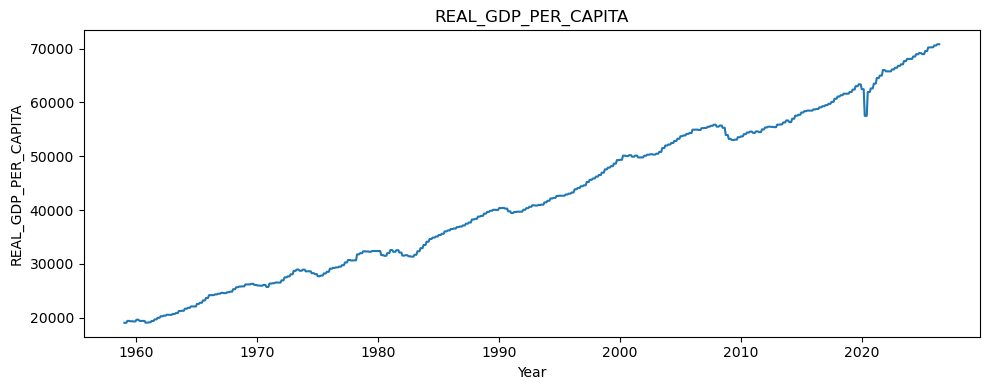

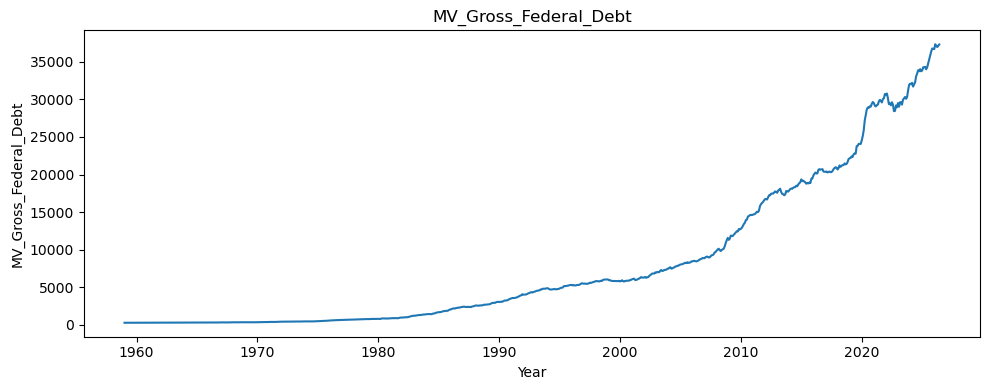

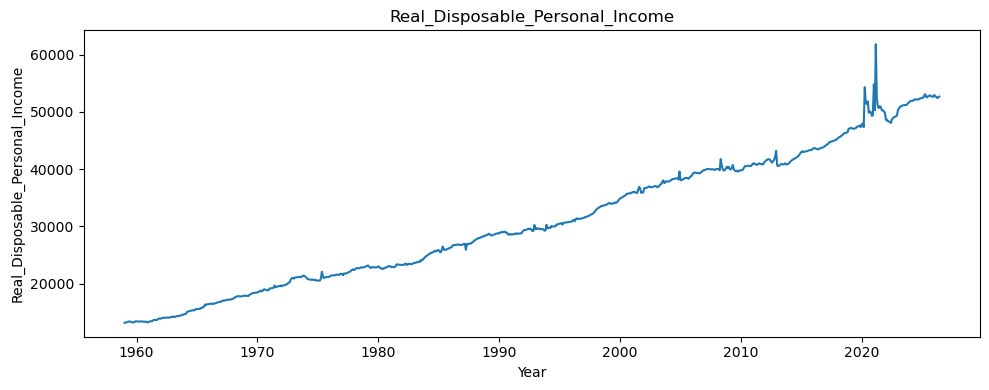

In [2118]:
raw_features = final_data.columns.drop("Date")

for col in raw_features:
    plt.figure(figsize=(10, 4))

    sns.lineplot(data=final_data, x="Date", y=col)

    plt.title(col)
    plt.xlabel("Year")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

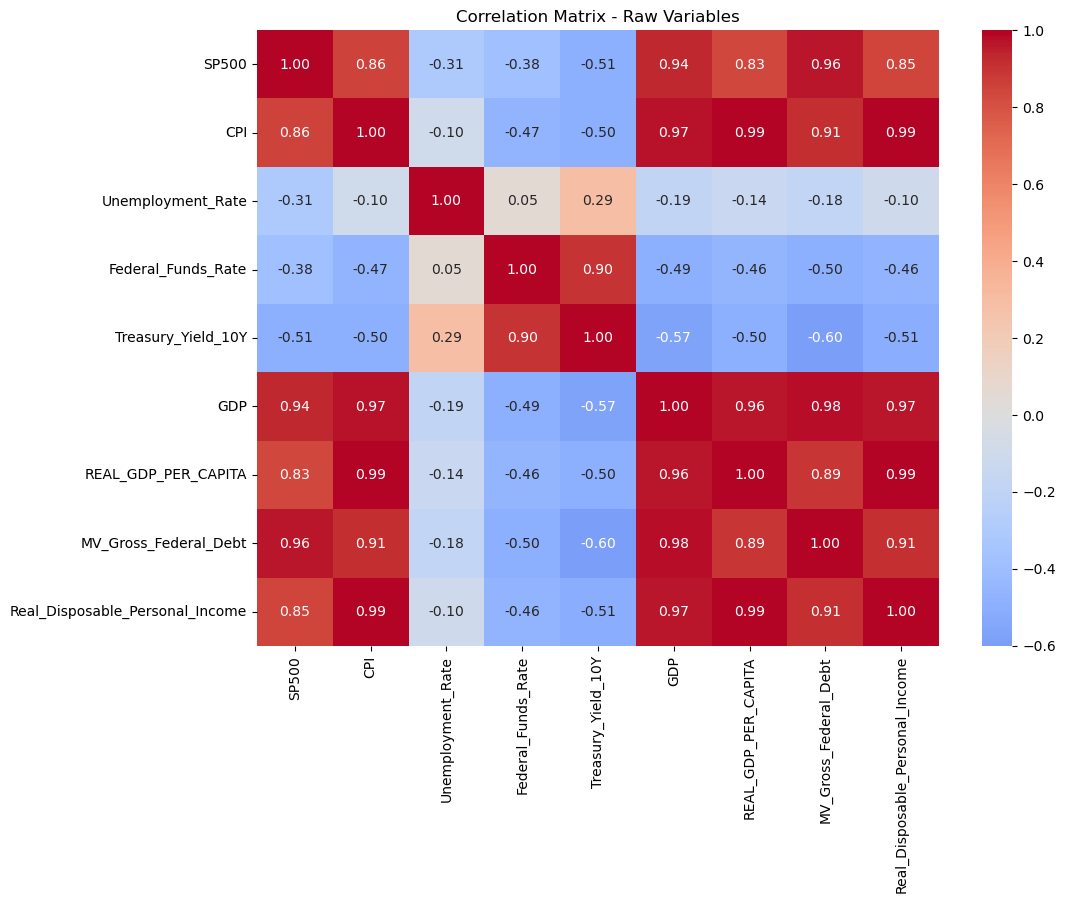

In [2119]:
plt.figure(figsize=(11, 8))

corr_raw = final_data[raw_features].corr()

sns.heatmap(
    corr_raw,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix - Raw Variables")
plt.show()

### Correlation Heatmap Key Findings

The S&P 500 has strong positive correlations with federal debt (0.96), GDP (0.94), and CPI (0.86). Returns and growth rates will be used to reduce the influence of these trends.

### 8. Feature Engineering

Several raw variables have strong historical trends. Returns, growth rates, interest-rate changes, and market volatility measures were created to better compare economic conditions over time.

### Engineered Features

The following features were created:

- **Market Returns:** (i) Monthly and (ii) 12-month S&P 500 percentage returns.
- **Market Volatility:** (iii) Rolling six-month standard deviation of monthly returns.
- **Inflation:** (iv)  Year-over-year CPI percentage change.
- **Unemployment:** (v) Change in the unemployment rate over 12 months.
- **Interest Rates:** Annual changes in the (vi) Federal Funds Rate and (vii) 10-Year Treasury Yield.
- **Yield Spread:** (viii) Difference between the 10-Year Treasury Yield and Federal Funds Rate.
- **Economic Growth:** Year-over-year growth in (ix) GDP, (x) real GDP per capita, (xi) federal debt, and (xii) real disposable personal income.

In [2120]:
model_data = final_data.copy()

In [2121]:
model_data["SP500_Monthly_Return"] = (model_data["SP500"].pct_change(fill_method=None) * 100) #(i)

In [2122]:
model_data["SP500_12M_Return"] = (model_data["SP500"].pct_change(12, fill_method=None) * 100) #(ii)

In [2123]:
model_data["SP500_Volatility_6M"] = (model_data["SP500_Monthly_Return"].rolling(6).std()) #(iii)

In [2124]:
model_data["Inflation_YoY"] = (model_data["CPI"].pct_change(12, fill_method=None) * 100) #(iv)

In [2125]:
model_data["Unemployment_Change_12M"] = (model_data["Unemployment_Rate"].diff(12)) #(v)

In [2126]:
model_data["Fed_Funds_Change_12M"] = (model_data["Federal_Funds_Rate"].diff(12)) #(vi)

In [2127]:
model_data["Treasury_10Y_Change_12M"] = (model_data["Treasury_Yield_10Y"].diff(12)) #(vii)

In [2128]:
model_data["Yield_Spread_10Y_FedFunds"] = (model_data["Treasury_Yield_10Y"] - model_data["Federal_Funds_Rate"]) #(viii)

In [2129]:
model_data["GDP_Growth_YoY"] = (model_data["GDP"].pct_change(12, fill_method=None) * 100) #(ix)

In [2130]:
model_data["Real_GDP_Per_Capita_Growth_YoY"] = (model_data["REAL_GDP_PER_CAPITA"].pct_change(12, fill_method=None) * 100) #(x)

In [2131]:
model_data["Federal_Debt_Growth_YoY"] = (model_data["MV_Gross_Federal_Debt"].pct_change(12, fill_method=None) * 100) #(xi)

In [2132]:
model_data["Disposable_Income_Growth_YoY"] = (model_data["Real_Disposable_Personal_Income"].pct_change(12, fill_method=None) * 100) #(xii)

In [2133]:
model_features = [
    "SP500_Monthly_Return",
    "SP500_12M_Return",
    "SP500_Volatility_6M",
    
    "Inflation_YoY",
    
    "Unemployment_Rate",
    "Unemployment_Change_12M",
    
    "Federal_Funds_Rate",
    "Fed_Funds_Change_12M",
    
    "Treasury_Yield_10Y",
    "Treasury_10Y_Change_12M",
    "Yield_Spread_10Y_FedFunds",
    
    "GDP_Growth_YoY",
    "Real_GDP_Per_Capita_Growth_YoY",
    
    "Federal_Debt_Growth_YoY",
    "Disposable_Income_Growth_YoY"
]

In [2134]:
model_data[model_features].isna().sum()

SP500_Monthly_Return               1
SP500_12M_Return                  12
SP500_Volatility_6M                6
Inflation_YoY                     12
Unemployment_Rate                  0
Unemployment_Change_12M           12
Federal_Funds_Rate                 0
Fed_Funds_Change_12M              12
Treasury_Yield_10Y                 0
Treasury_10Y_Change_12M           12
Yield_Spread_10Y_FedFunds          0
GDP_Growth_YoY                    12
Real_GDP_Per_Capita_Growth_YoY    12
Federal_Debt_Growth_YoY           12
Disposable_Income_Growth_YoY      12
dtype: int64

### Preparing the Modeling Dataset

Some features require up to 12 months of previous data. Rows with missing engineered features were removed before proceeding with PCA and clustering.

In [2135]:
ml_data = (model_data[["Date"] + model_features].dropna().reset_index(drop=True))

In [2136]:
print("Modeling observations:", len(ml_data))
print("Start:", ml_data["Date"].min())
print("End:", ml_data["Date"].max())

ml_data.head()

Modeling observations: 798
Start: 1960-01-01 00:00:00
End: 2026-06-01 00:00:00


,Date,SP500_Monthly_Return,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Unemployment_Change_12M,Federal_Funds_Rate,Fed_Funds_Change_12M,Treasury_Yield_10Y,Treasury_10Y_Change_12M,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY,Real_GDP_Per_Capita_Growth_YoY,Federal_Debt_Growth_YoY,Disposable_Income_Growth_YoY
0,1960-01-01,-1.743989,4.332974,2.372621,1.240951,5.2,-0.8,3.99,1.51,4.72,0.70,0.73,6.332765,3.009296,0.694191,1.933869
1,1960-02-01,-3.877305,1.844075,2.756566,1.413793,4.8,-1.1,3.97,1.54,4.49,0.53,0.52,6.332765,3.009296,0.656216,1.544402
2,1960-03-01,-1.362496,-2.029915,2.379896,1.518813,5.4,-0.2,3.84,1.04,4.25,0.26,0.41,6.332765,3.009296,2.481481,1.002487
3,1960-04-01,1.290440,-2.399299,2.500187,1.932367,5.2,0.0,3.92,0.96,4.28,0.16,0.36,3.525666,-0.015468,1.875690,0.667367
4,1960-05-01,-0.915127,-4.727398,2.478705,1.825069,5.1,0.0,3.85,0.95,4.35,0.04,0.50,3.525666,-0.015468,2.240176,0.276284


In [2137]:
ml_data[model_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SP500_Monthly_Return,798.0,0.67,3.54,-20.39,-1.01,0.99,2.89,12.02
SP500_12M_Return,798.0,8.64,15.51,-42.51,-0.45,10.18,18.99,52.65
SP500_Volatility_6M,798.0,3.01,1.54,0.43,1.98,2.67,3.73,9.91
Inflation_YoY,798.0,3.74,2.78,-1.96,1.89,3.01,4.64,14.59
Unemployment_Rate,798.0,5.85,1.69,3.40,4.60,5.60,6.90,14.80
Unemployment_Change_12M,798.0,-0.02,1.35,-8.70,-0.60,-0.30,0.30,11.10
Federal_Funds_Rate,798.0,4.78,3.60,0.05,2.00,4.66,6.49,19.10
Fed_Funds_Change_12M,798.0,0.01,2.08,-7.70,-0.85,0.03,0.97,10.01
Treasury_Yield_10Y,798.0,5.76,2.91,0.62,3.88,5.22,7.46,15.32
Treasury_10Y_Change_12M,798.0,-0.00,1.11,-4.24,-0.64,0.06,0.64,4.03


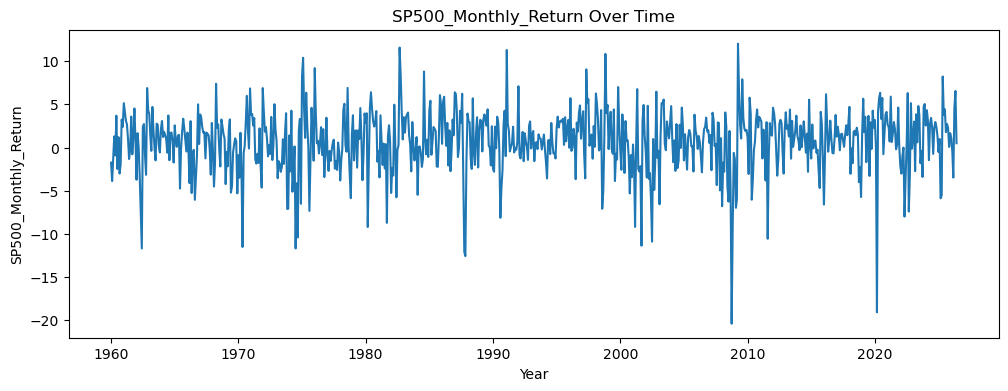

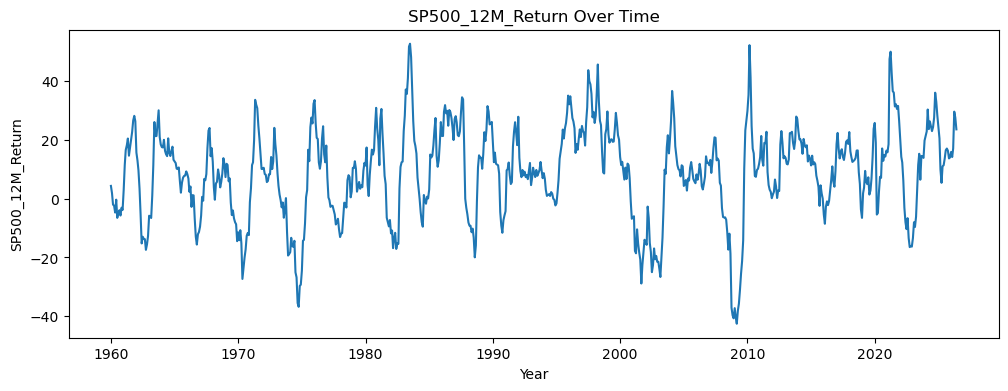

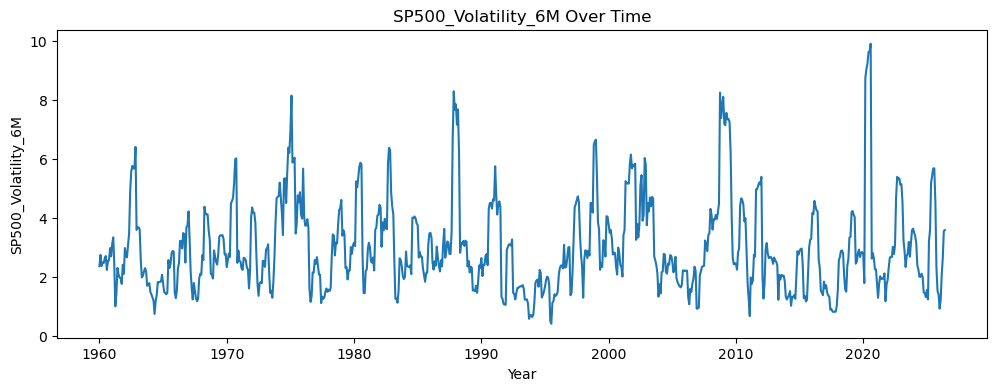

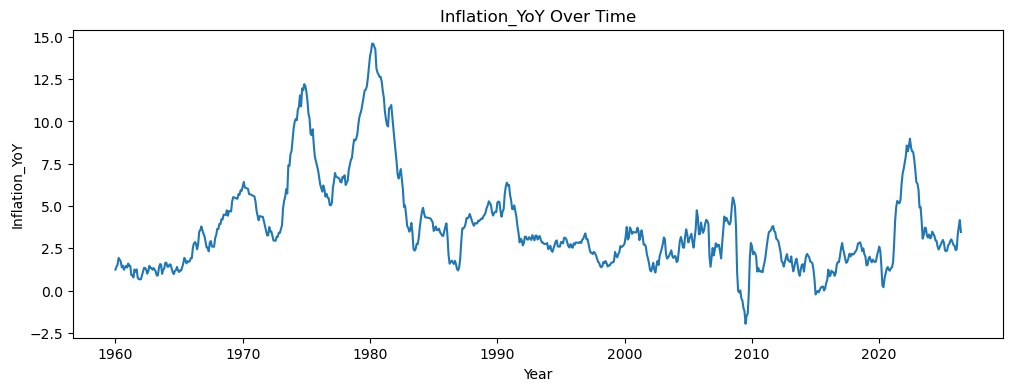

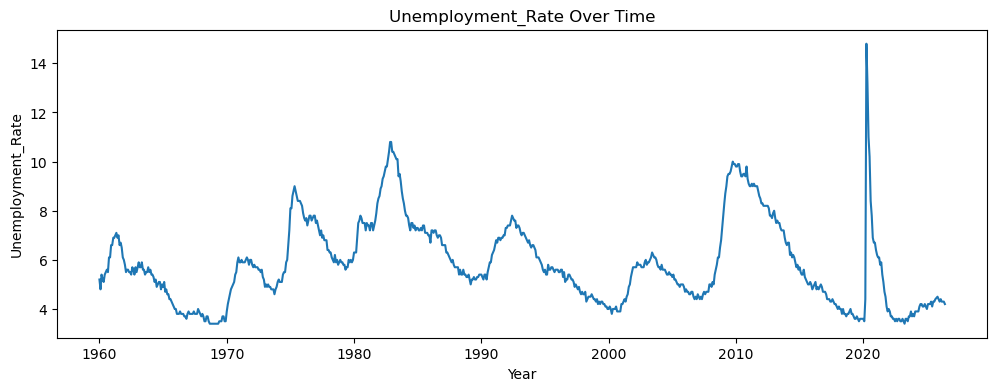

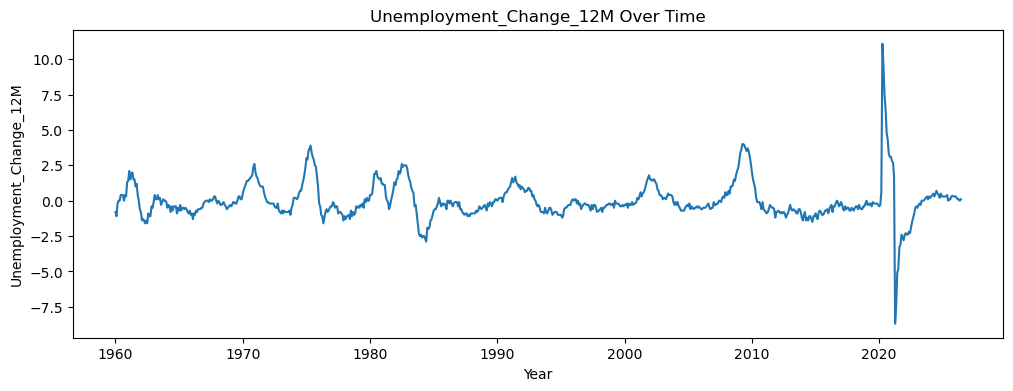

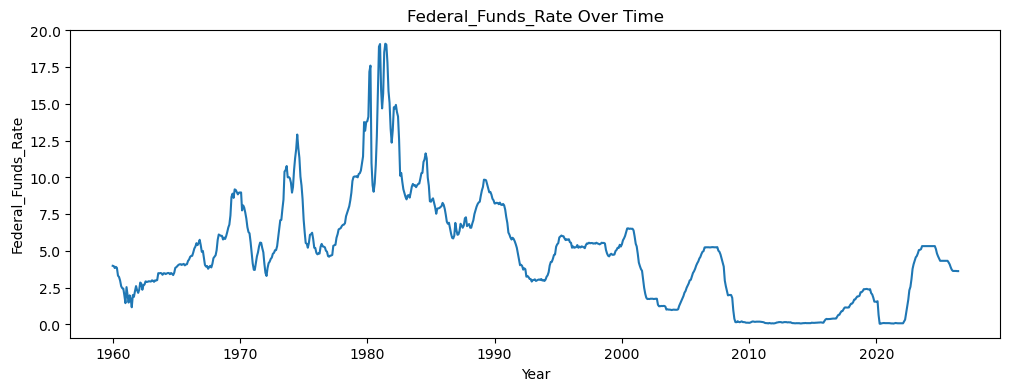

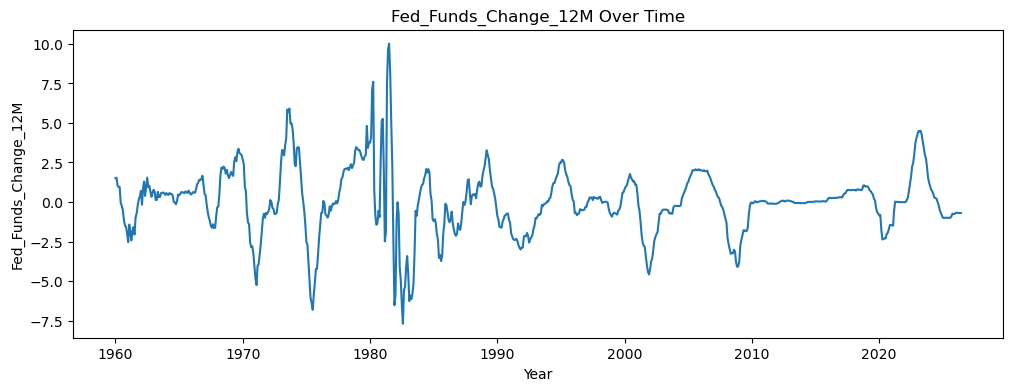

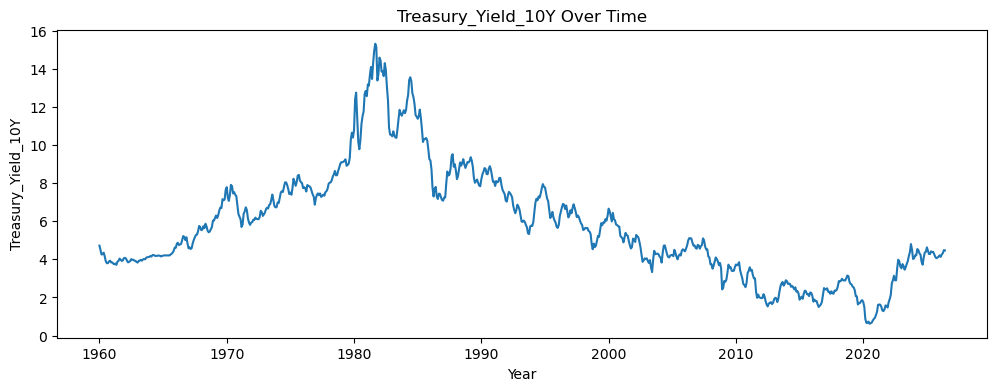

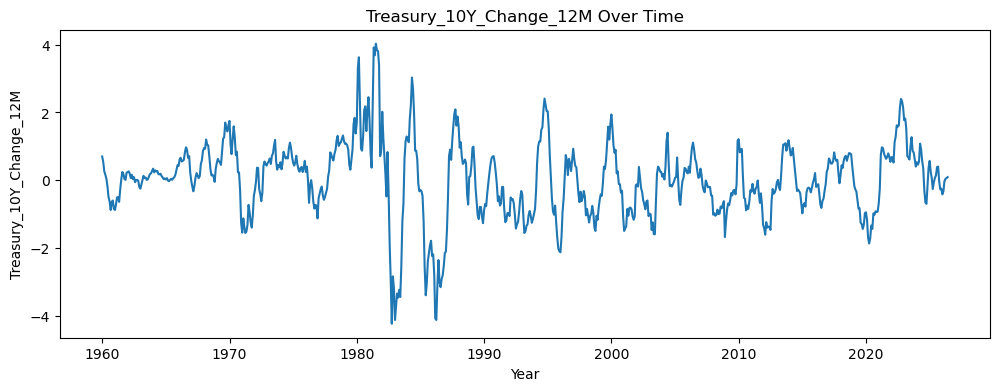

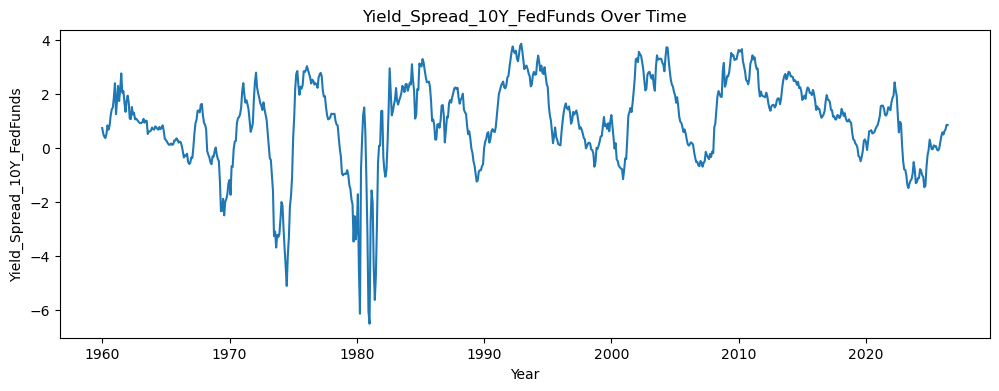

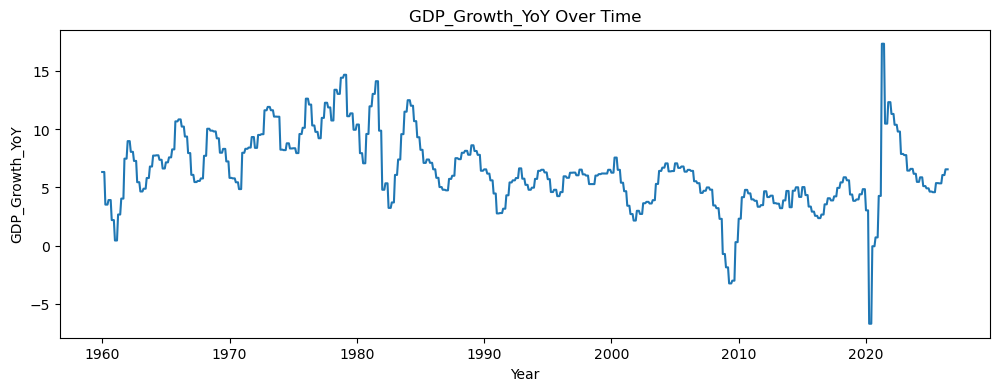

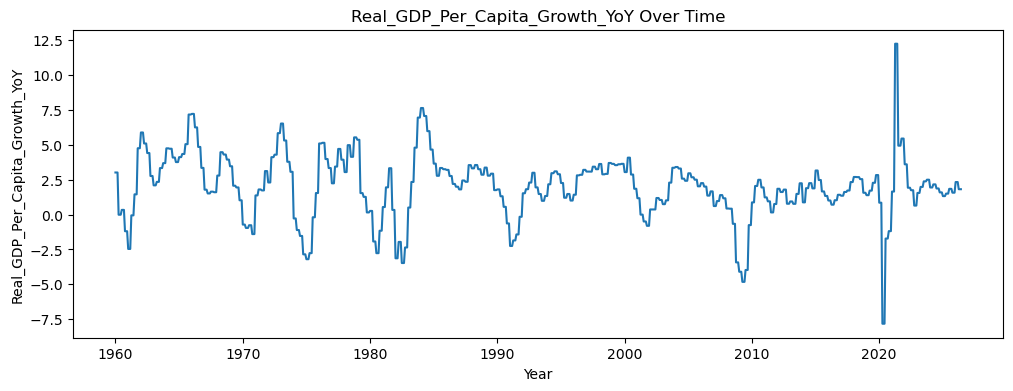

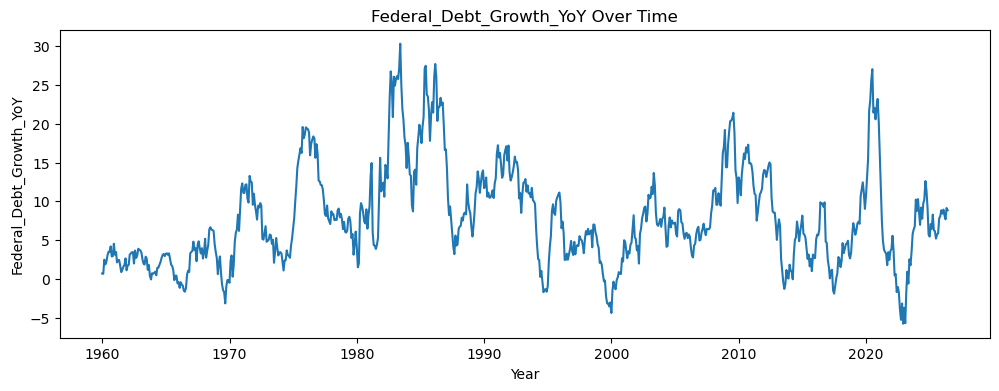

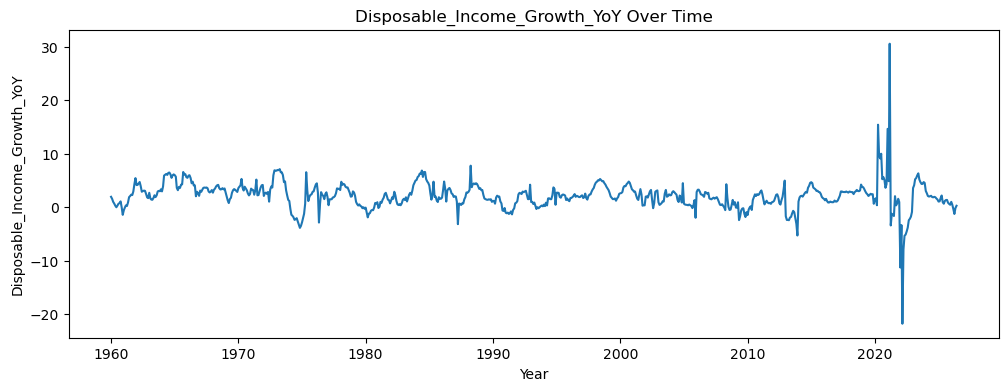

In [2138]:
for col in model_features:
    
    plt.figure(figsize=(12, 4))
    
    sns.lineplot(
        data=ml_data,
        x="Date",
        y=col
    )
    
    plt.title(f"{col} Over Time")
    plt.xlabel("Year")
    plt.ylabel(col)
    plt.show()

### Correlation of Engineered Features

Correlations between the engineered features were reviewed to identify variables that may contain similar information before PCA.

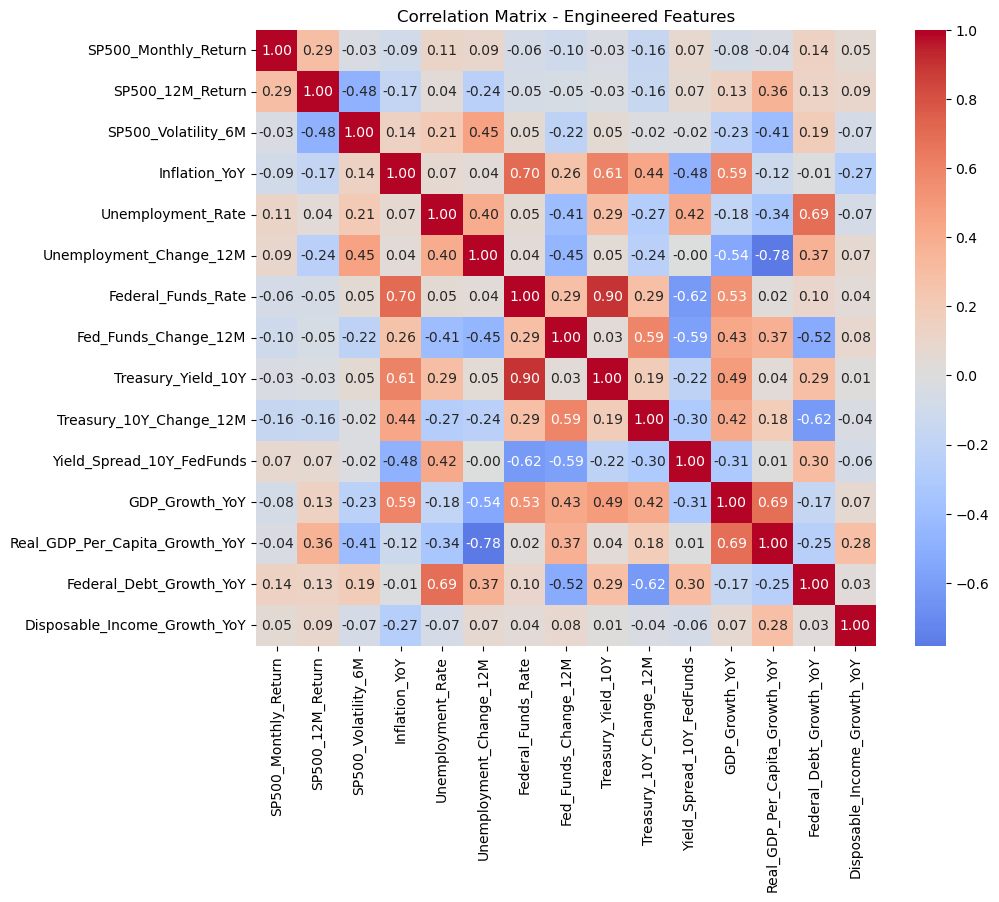

In [2139]:
plt.figure(figsize=(10, 8))

corr_engineered = (
    ml_data[model_features]
    .corr()
)

sns.heatmap(
    corr_engineered,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix - Engineered Features")
plt.show()

### Correlation Analysis - Engineered Features

The engineered features have weaker correlations with monthly S&P 500 returns. However, the Federal Funds Rate and 10-Year Treasury Yield remain strongly correlated (0.90), as do unemployment change and real GDP per capita growth (-0.78). PCA may help summarize some of these relationships.

### Distribution and Outlier Review

The distributions of selected features were reviewed to identify extreme observations. These observations were retained because they may represent important economic events.

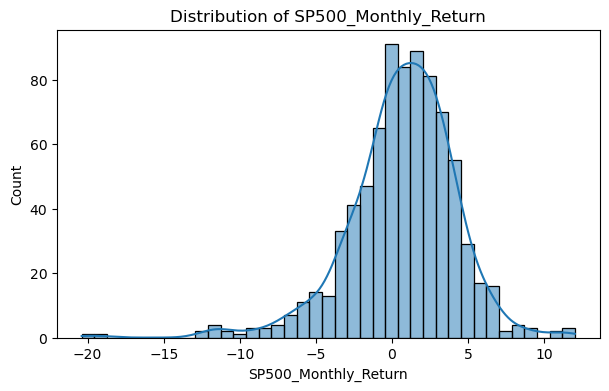

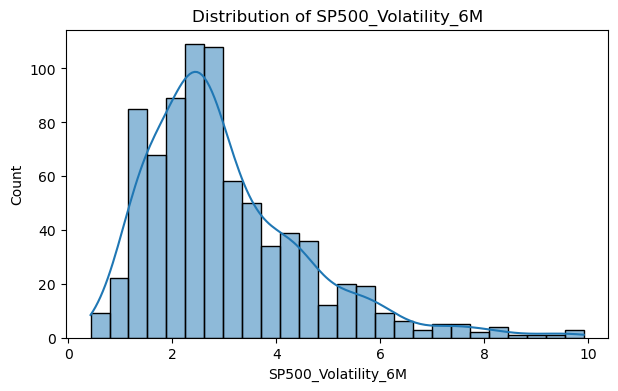

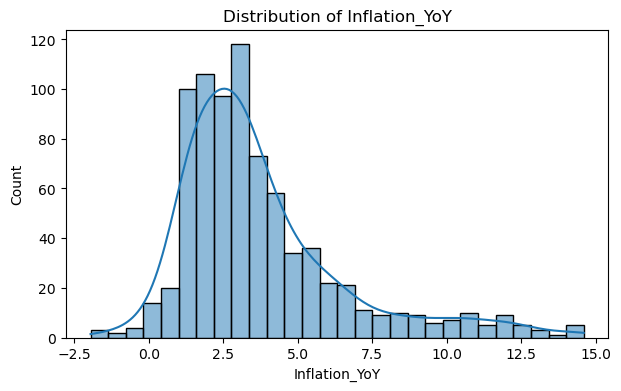

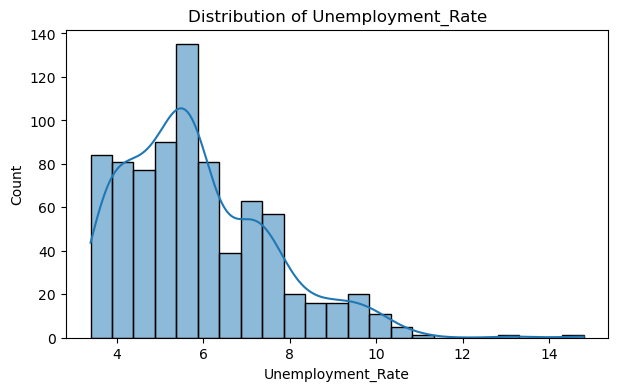

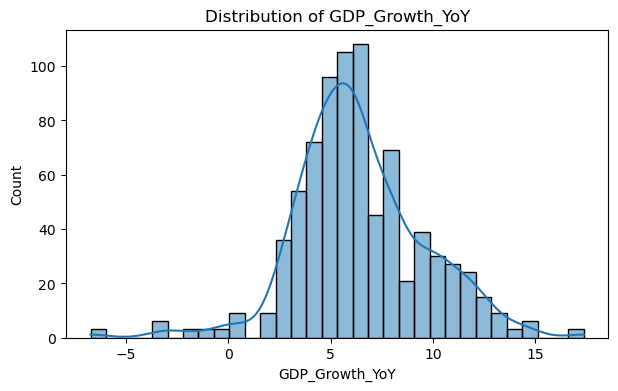

In [2140]:
features_to_plot = [
    "SP500_Monthly_Return",
    "SP500_Volatility_6M",
    "Inflation_YoY",
    "Unemployment_Rate",
    "GDP_Growth_YoY"
]

for col in features_to_plot:
    
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        ml_data[col],
        kde=True
    )
    
    plt.title(f"Distribution of {col}")
    plt.show()

### Loading NBER Recession Data

The monthly USREC indicator from FRED, based on NBER recession dates, was used to evaluate how the identified market regimes align with historical U.S. recessions.

- 1: Recession month
- 0: Non-recession month

This indicator will be used for historical cluster evaluation and as the target variable for supervised recession classification. It will NOT be included in the PCA or clustering features.

In [2141]:
# Load monthly NBER recession indicator
usrec = pd.read_csv("data/USREC.csv")

# Convert dates to datetime
usrec["observation_date"] = pd.to_datetime(usrec["observation_date"])

# Rename columns to match the modeling dataset
usrec = usrec.rename(columns={
    "observation_date": "Date",
    "USREC": "NBER_Recession"
})

print(usrec.head())
print(usrec.tail())

        Date  NBER_Recession
0 1854-12-01               1
1 1855-01-01               0
2 1855-02-01               0
3 1855-03-01               0
4 1855-04-01               0
           Date  NBER_Recession
2057 2026-05-01               0
2058 2026-06-01               0
2059 2026-07-01               0
2060 2026-08-01               0
2061 2026-09-01               0


In [2142]:
# Remove recession columns from previous merges
ml_data = ml_data.drop(
    columns=["NBER_Recession", "NBER_Recession_x", "NBER_Recession_y"],
    errors="ignore"
)

# Merge the recession indicator
ml_data = ml_data.merge(
    usrec[["Date", "NBER_Recession"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

# Verify the merge
print("Dataset shape:", ml_data.shape)
print("Missing recession labels:", ml_data["NBER_Recession"].isna().sum())
print(ml_data[["Date", "NBER_Recession"]].head())

Dataset shape: (798, 17)
Missing recession labels: 0
        Date  NBER_Recession
0 1960-01-01               0
1 1960-02-01               0
2 1960-03-01               0
3 1960-04-01               0
4 1960-05-01               1


## 9. Standardization

The dataset is divided chronologically into training (January 1960–December 1999) and testing (January 2000–June 2026) periods.

StandardScaler was used to standardize the 15 features. The scaler was fitted on the training data and then applied to the test data to avoid data leakage.

In [2143]:
# Sort observations by date
ml_data = ml_data.sort_values("Date").reset_index(drop=True)

# Split the data before and after January 2000
train_data = ml_data[ml_data["Date"] < "2000-01-01"].copy()
test_data = ml_data[ml_data["Date"] >= "2000-01-01"].copy()

# Select modeling features
X_train = train_data[model_features]
X_test = test_data[model_features]

# Fit scaler on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Testing:", test_data["Date"].min(), "to", test_data["Date"].max())

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

Training: 1960-01-01 00:00:00 to 1999-12-01 00:00:00
Testing: 2000-01-01 00:00:00 to 2026-06-01 00:00:00
Training observations: 480
Testing observations: 318


In [2144]:
# Create DataFrames for scaled features
train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=model_features,
    index=train_data.index
)

test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=model_features,
    index=test_data.index
)

train_scaled.head()

,SP500_Monthly_Return,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Unemployment_Change_12M,Federal_Funds_Rate,Fed_Funds_Change_12M,Treasury_Yield_10Y,Treasury_10Y_Change_12M,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY,Real_GDP_Per_Capita_Growth_YoY,Federal_Debt_Growth_YoY,Disposable_Income_Growth_YoY
0,-0.721659,-0.327042,-0.406348,-1.060528,-0.539734,-0.750270,-0.802439,0.617217,-1.035506,0.524030,-0.016630,-0.467424,0.278229,-1.104601,-0.235195
1,-1.345249,-0.493107,-0.131562,-1.004248,-0.806957,-1.042900,-0.808589,0.629827,-1.125798,0.390552,-0.139166,-0.467424,0.278229,-1.110207,-0.430953
2,-0.610145,-0.751588,-0.401141,-0.970052,-0.406123,-0.165011,-0.848569,0.419657,-1.220016,0.178559,-0.203351,-0.467424,0.278229,-0.840791,-0.703335
3,0.165335,-0.776234,-0.315050,-0.835392,-0.539734,0.030076,-0.823966,0.386030,-1.208239,0.100043,-0.232526,-1.506858,-1.019783,-0.930208,-0.871776
4,-0.479374,-0.931570,-0.330425,-0.870330,-0.606540,0.030076,-0.845494,0.381827,-1.180759,0.005823,-0.150836,-1.506858,-1.019783,-0.876408,-1.068345


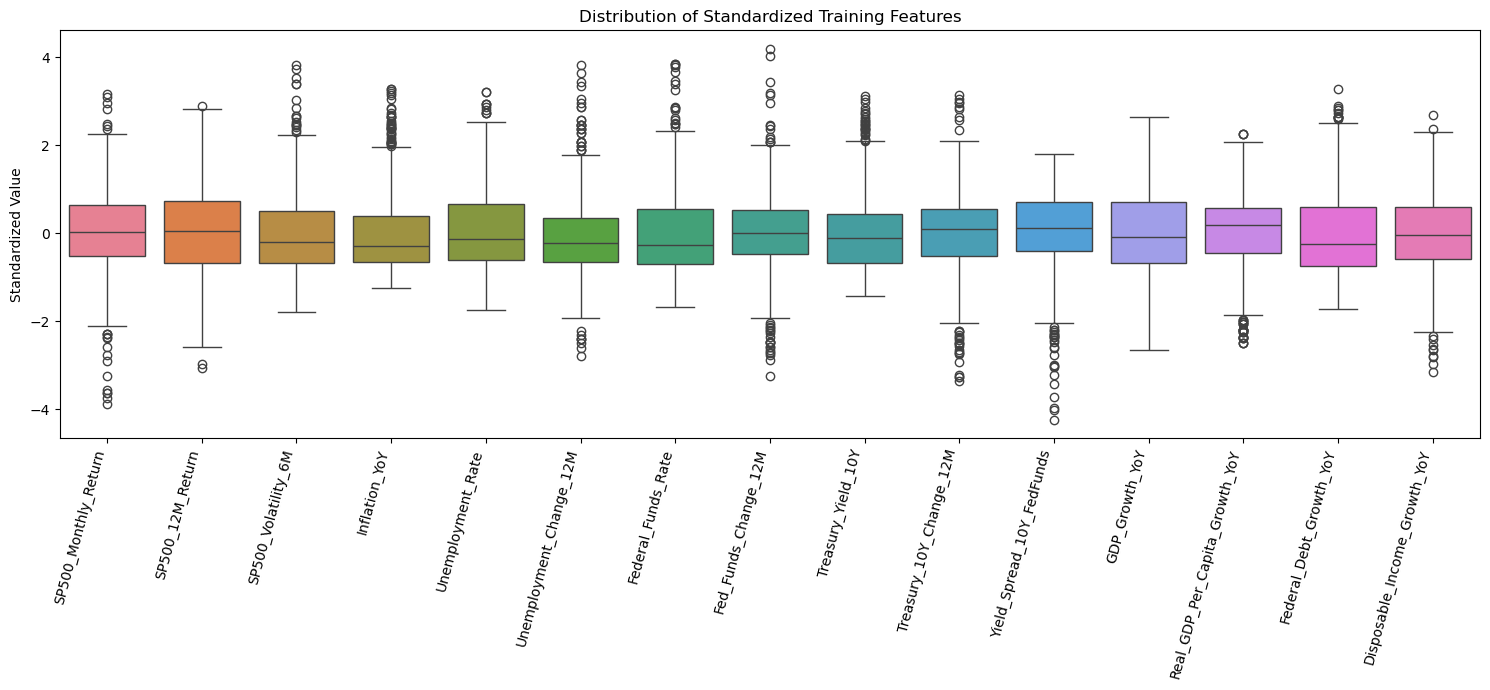

In [2145]:
plt.figure(figsize=(15, 7))

sns.boxplot(data=train_scaled)

plt.xticks(rotation=75, ha="right")
plt.title("Distribution of Standardized Training Features")
plt.ylabel("Standardized Value")

plt.tight_layout()
plt.show()

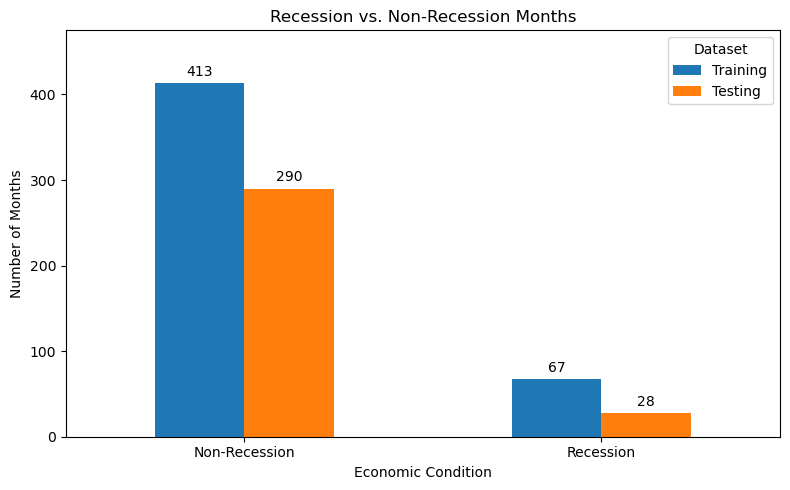

In [2146]:
# Compare recession and non-recession months
recession_counts = pd.DataFrame({
    "Training": train_data["NBER_Recession"].value_counts(),
    "Testing": test_data["NBER_Recession"].value_counts()
}).reindex([0, 1]).fillna(0).astype(int)

recession_counts.index = ["Non-Recession", "Recession"]

# Plot the comparison
ax = recession_counts.plot(kind="bar", figsize=(8, 5), rot=0)

# Display values above each bar
for bars in ax.containers:
    ax.bar_label(bars, padding=3)

plt.title("Recession vs. Non-Recession Months")
plt.xlabel("Economic Condition")
plt.ylabel("Number of Months")
plt.legend(title="Dataset")
plt.ylim(0, recession_counts.to_numpy().max() * 1.15)
plt.tight_layout()
plt.show()

## 10. Principal Component Analysis (PCA)

Several economic indicators are correlated, so PCA was used to reduce the number of features before clustering. PCA was fitted on the standardized training data and then applied to the test data.

In [2147]:
# Fit PCA on training data
pca = PCA()

pca.fit(train_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()

In [2148]:
# Create a table showing the variance explained by each component
pca_results = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": cumulative_variance
})

pca_results.round(3)

,Component,Explained_Variance,Cumulative_Variance
0,1,0.265,0.265
1,2,0.260,0.525
2,3,0.149,0.674
3,4,0.077,0.751
4,5,0.065,0.816
5,6,0.045,0.861
6,7,0.038,0.899
7,8,0.035,0.934
8,9,0.034,0.968
9,10,0.014,0.982


### Selecting the Number of Principal Components

Cumulative explained variance was used to determine how many principal components to retain.

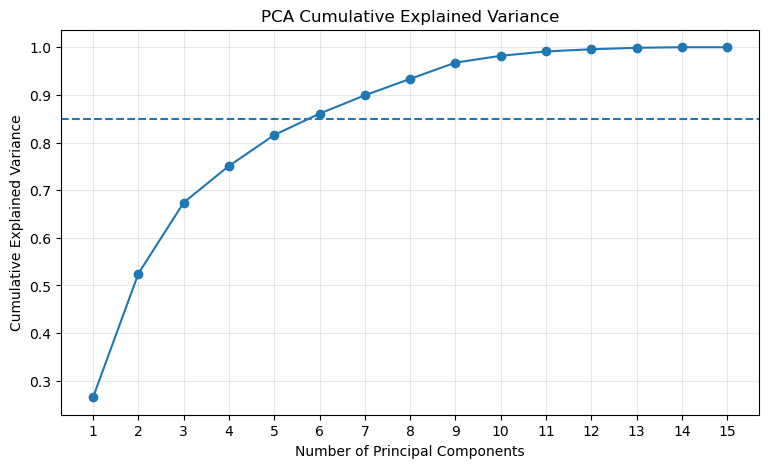

In [2149]:
# Plot cumulative explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

# Reference line for 85% explained variance
plt.axhline(y=0.85, linestyle="--")

plt.title("PCA Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(alpha=0.3)

plt.show()

In [2150]:
print("Variance explained by 6 PCs:",
      round(cumulative_variance[5] * 100, 2), "%")

Variance explained by 6 PCs: 86.06 %


### PCA Selection

Six principal components were selected, explaining 86.1% of the variation in the training data. This reduces the original 15 features to six components for clustering.

In [2151]:
# Fit final PCA on training data only
pca_final = PCA(n_components=6)

X_train_pca = pca_final.fit_transform(train_scaled)

# Apply the same PCA to test data
X_test_pca = pca_final.transform(test_scaled)

In [2152]:
# Create PCA DataFrames
pca_columns = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"]

train_pca = pd.DataFrame(
    X_train_pca,
    columns=pca_columns,
    index=train_data.index
)

test_pca = pd.DataFrame(
    X_test_pca,
    columns=pca_columns,
    index=test_data.index
)

train_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6
0,-0.629647,1.872159,-1.176614,-0.280456,-0.814474,0.353543
1,-0.446314,2.062105,-1.388687,-0.576410,-1.166001,-0.088219
2,-0.669404,1.282591,-1.501849,-0.290375,-0.818922,0.171232
3,-0.895316,0.403755,-2.523830,0.330048,-0.511568,0.490908
4,-0.833749,0.403055,-2.614766,0.011497,-1.051087,0.267915


### Understanding the Principal Components

PCA loadings show how strongly each original feature contributes to the principal components.

In [2153]:
# Show how the original features contribute to each component
loadings = pd.DataFrame(
    pca_final.components_.T,
    index=model_features,
    columns= ("PC1", "PC2", "PC3", "PC4", "PC5", "PC6")
)

loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6
SP500_Monthly_Return,-0.15,-0.11,0.04,0.40,0.74,0.39
SP500_12M_Return,-0.23,-0.02,0.27,0.54,-0.00,-0.02
SP500_Volatility_6M,0.16,-0.16,-0.17,-0.38,0.56,-0.38
Inflation_YoY,0.42,-0.19,0.01,0.03,0.06,0.10
Unemployment_Rate,-0.00,-0.39,0.31,-0.17,-0.10,0.22
Unemployment_Change_12M,0.01,-0.39,-0.29,0.05,0.08,-0.09
Federal_Funds_Rate,0.42,-0.15,0.19,0.20,-0.04,-0.15
Fed_Funds_Change_12M,0.30,0.33,-0.01,0.22,-0.06,0.06
Treasury_Yield_10Y,0.30,-0.25,0.35,-0.04,-0.05,0.11
Treasury_10Y_Change_12M,0.35,0.19,-0.11,-0.18,0.06,0.51


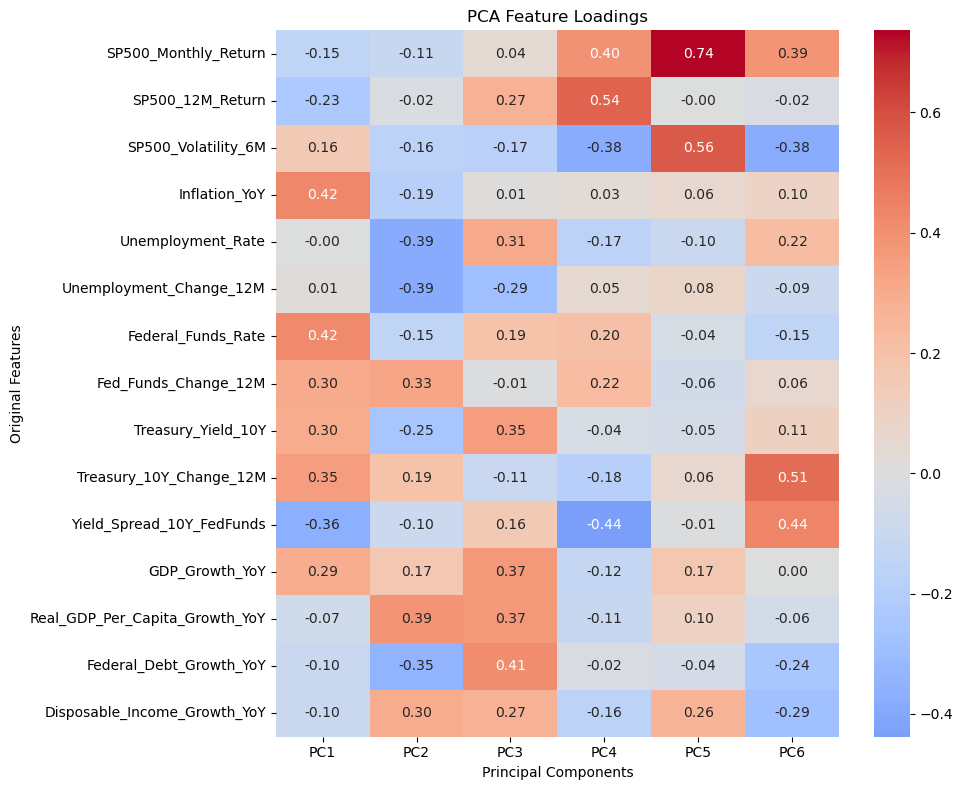

In [2154]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("PCA Feature Loadings")
plt.xlabel("Principal Components")
plt.ylabel("Original Features")

plt.tight_layout()
plt.show()

In [2155]:
print("Training PCA shape:", train_pca.shape)
print("Testing PCA shape:", test_pca.shape)

Training PCA shape: (480, 6)
Testing PCA shape: (318, 6)


### PCA Feature Loadings Interpretation

The PCA loadings show how different economic indicators contribute to the six components.

- **PC1:** Inflation, interest rates, and yield-spread conditions.
- **PC2:** Employment and real economic growth.
- **PC3:** Federal debt growth, GDP growth, and unemployment.
- **PC4:** Stock market performance and yield spreads.
- **PC5:** Stock market returns and volatility.
- **PC6:** Treasury yield changes, yield spreads, and market returns.

Together, the six components explain 86.1% of the training-data variance and are used for K-Means, GMM, and DBSCAN.

## 11. K-Means Clustering

K-Means was used to group months with similar economic and financial conditions. The model was fitted using the six PCA components from the training period. Different numbers of clusters were compared using the Elbow Method and Silhouette Score.

In [2156]:
# Suppress the specific KMeans MKL memory leak warning
warnings.filterwarnings(
    "ignore", message="KMeans is known to have a memory leak"
)

# Test different numbers of clusters
k_values = range(2, 11)

inertia = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(train_pca)

    inertia.append(kmeans.inertia_)

### Elbow Method

Inertia decreases as the number of clusters increases, with smaller improvements after approximately five clusters. Since there is no clear elbow, silhouette scores and economic characteristics were also considered before selecting the final number of clusters.

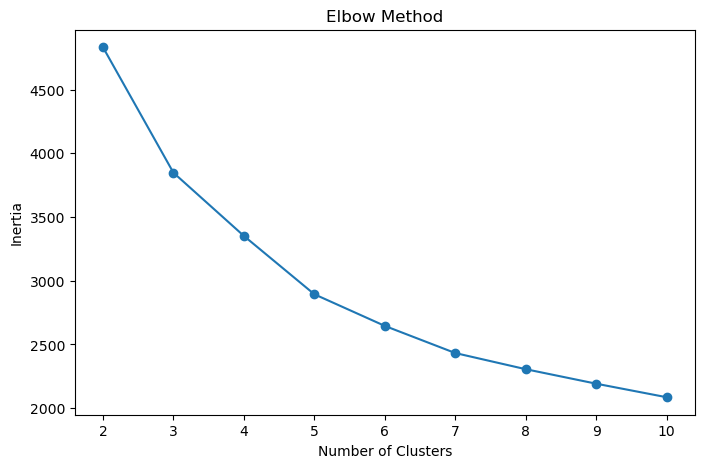

In [2157]:
# Plot the Elbow Method results
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

### Silhouette Score

The silhouette score measures how well observations fit within their assigned clusters compared with other clusters. Higher scores generally indicate better-separated clusters.

In [2158]:
# Calculate silhouette score for each number of clusters
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(train_pca)

    score = silhouette_score(train_pca, labels)

    silhouette_scores.append(score)

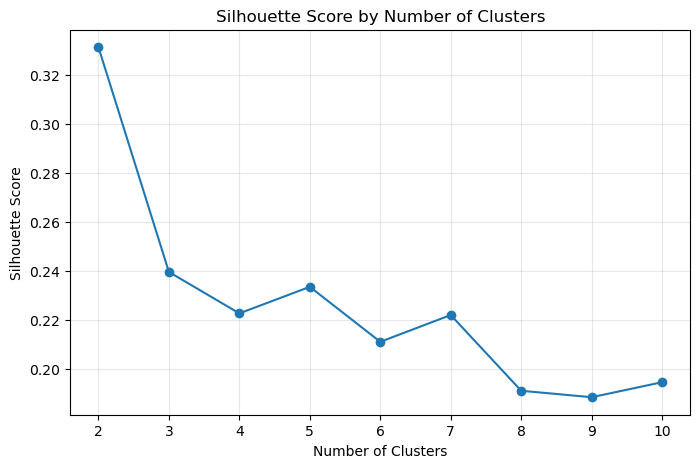

In [2159]:
# Plot silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [2160]:
# Compare the results
cluster_results = pd.DataFrame({
    "Number_of_Clusters": list(k_values),
    "Inertia": inertia,
    "Silhouette_Score": silhouette_scores
})

cluster_results.round(3)

,Number_of_Clusters,Inertia,Silhouette_Score
0,2,4833.486,0.331
1,3,3848.375,0.240
2,4,3351.967,0.223
3,5,2893.844,0.234
4,6,2645.394,0.211
5,7,2432.229,0.222
6,8,2305.392,0.191
7,9,2191.611,0.189
8,10,2085.293,0.195


In [2161]:
# Compare economic characteristics of different K-Means solutions
key_features = [
    "SP500_12M_Return",
    "SP500_Volatility_6M",
    "Inflation_YoY",
    "Unemployment_Rate",
    "Yield_Spread_10Y_FedFunds",
    "GDP_Growth_YoY"
]

for k in [2, 3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(train_pca)

    profiles = train_data[key_features].copy()
    profiles["Cluster"] = labels

    print(f"\n{k} Clusters - Economic Profiles:")
    display(profiles.groupby("Cluster")[key_features].mean().round(2))


2 Clusters - Economic Profiles:


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,-0.86,4.18,9.08,7.00,-0.67,8.13
1,11.83,2.62,3.32,5.75,1.12,7.46



3 Clusters - Economic Profiles:


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,8.46,2.78,3.31,5.19,0.73,7.94
1,15.63,2.78,3.95,7.17,1.92,6.13
2,-2.11,3.94,10.48,6.66,-1.77,9.49



4 Clusters - Economic Profiles:


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,2.83,3.15,5.55,6.31,1.02,10.97
1,15.87,2.73,3.90,7.17,1.89,5.93
2,11.01,2.69,2.63,4.88,0.66,6.95
3,-3.06,3.96,10.57,6.75,-1.77,9.06



5 Clusters - Economic Profiles:


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,3.00,3.24,5.46,6.37,1.24,10.97
1,-3.61,4.85,7.79,7.67,1.02,5.93
2,11.33,2.70,2.40,4.91,0.82,6.89
3,19.67,2.19,3.43,6.93,1.78,6.28
4,-0.66,3.21,9.92,5.68,-2.77,9.95


In [2162]:
# Compare K-Means clusters and historical recession periods
for k in [2, 3, 4, 5]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(train_pca)

    comparison = pd.DataFrame({
        "Cluster": labels,
        "NBER_Recession": train_data["NBER_Recession"].to_numpy()
    })

    summary = comparison.groupby("Cluster")["NBER_Recession"].agg(
        Total_Months="count",
        Recession_Months="sum",
        Recession_Rate="mean"
    )

    summary["Recession_Rate"] = (
        summary["Recession_Rate"] * 100
    ).round(1)

    print(f"\n{k} Clusters - Historical Recession Alignment:")
    display(summary)


2 Clusters - Historical Recession Alignment:


,Total_Months,Recession_Months,Recession_Rate
Cluster,,,
0,98,56,57.1
1,382,11,2.9



3 Clusters - Historical Recession Alignment:


,Total_Months,Recession_Months,Recession_Rate
Cluster,,,
0,265,9,3.4
1,149,20,13.4
2,66,38,57.6



4 Clusters - Historical Recession Alignment:


,Total_Months,Recession_Months,Recession_Rate
Cluster,,,
0,79,0,0.0
1,137,18,13.1
2,202,10,5.0
3,62,39,62.9



5 Clusters - Historical Recession Alignment:


,Total_Months,Recession_Months,Recession_Rate
Cluster,,,
0,74,0,0.0
1,51,36,70.6
2,186,9,4.8
3,118,3,2.5
4,51,19,37.3


### Selecting the Number of Clusters

After comparing the Elbow Method, silhouette scores, cluster sizes, and economic characteristics, five clusters were selected.

Although two clusters had the highest silhouette score (0.331), they represented broad economic conditions. Five clusters had a lower silhouette score (0.234) but provided more detailed economic profiles.

The five-cluster solution also had reasonably sized groups, with at least 51 training observations in each cluster. Therefore, five clusters were selected to balance statistical performance with economic interpretation.

In [2163]:
# Fit K-Means on training PCA components
final_k = 5

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

train_clusters = kmeans_final.fit_predict(train_pca)

# Assign test observations to the existing clusters
test_clusters = kmeans_final.predict(test_pca)

In [2164]:
# Assign cluster labels
train_data["Cluster"] = train_clusters
test_data["Cluster"] = test_clusters

# Identify training and test observations
train_data["Dataset"] = "Train"
test_data["Dataset"] = "Test"

# Combine datasets for historical analysis
ml_data = pd.concat(
    [train_data, test_data]
).sort_values("Date").reset_index(drop=True)

ml_data[["Date", "Dataset", "Cluster"]].head()

,Date,Dataset,Cluster
0,1960-01-01,Train,2
1,1960-02-01,Train,2
2,1960-03-01,Train,2
3,1960-04-01,Train,2
4,1960-05-01,Train,2


In [2165]:
ml_data[["Date", "Dataset", "Cluster"]].tail()

,Date,Dataset,Cluster
793,2026-02-01,Test,2
794,2026-03-01,Test,2
795,2026-04-01,Test,2
796,2026-05-01,Test,2
797,2026-06-01,Test,2


In [2166]:
# Count the number of months in each cluster
cluster_counts = ml_data["Cluster"].value_counts().sort_index()

print(cluster_counts)

Cluster
0     77
1     76
2    431
3    163
4     51
Name: count, dtype: int64


In [2167]:
# Compare cluster distribution across training and testing periods
cluster_comparison = pd.crosstab(
    ml_data["Cluster"],
    ml_data["Dataset"]
)

cluster_comparison["Total"] = cluster_comparison.sum(axis=1)

display(cluster_comparison)


Dataset,Test,Train,Total
Cluster,,,
0,3,74,77
1,25,51,76
2,245,186,431
3,45,118,163
4,0,51,51


### Training vs. Testing Cluster Comparison

K-Means was fitted on the 1960–1999 training data and applied to the 2000–2026 test period.

Cluster 2 was the most common in the test period, accounting for 245 of 318 months (77%). Cluster 4, associated with high inflation and monetary tightening in the training data, had no test observations. Cluster 1 continued to show characteristics of market stress, including negative returns and higher volatility. However, the absence of Cluster 4 does not mean high inflation disappeared after 2000.

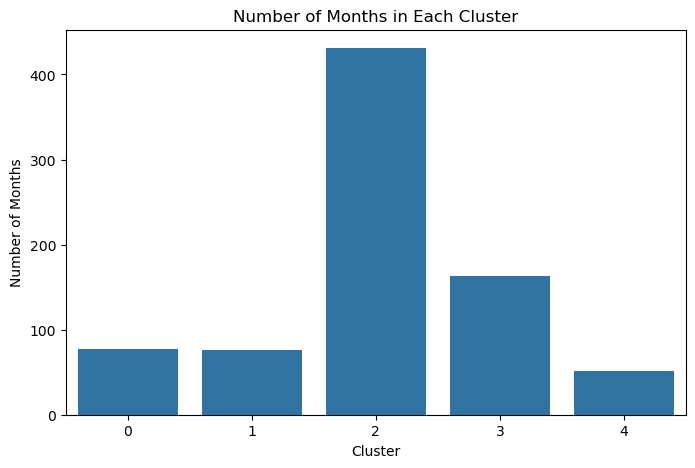

In [2168]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ml_data,
    x="Cluster",
    order=sorted(ml_data["Cluster"].unique())
)

plt.title("Number of Months in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Months")

plt.show()

In [2169]:
# Calculate the average feature value for each cluster
cluster_profile = (
    train_data
    .groupby("Cluster")[model_features]
    .mean()
    .round(2)
)

cluster_profile

,SP500_Monthly_Return,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Unemployment_Change_12M,Federal_Funds_Rate,Fed_Funds_Change_12M,Treasury_Yield_10Y,Treasury_10Y_Change_12M,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY,Real_GDP_Per_Capita_Growth_YoY,Federal_Debt_Growth_YoY,Disposable_Income_Growth_YoY
Cluster,,,,,,,,,,,,,,,
0,0.15,3.00,3.24,5.46,6.37,-1.05,7.78,1.32,9.02,0.70,1.24,10.97,4.75,10.02,4.04
1,1.76,-3.61,4.85,7.79,7.67,1.95,8.57,-2.94,9.59,0.13,1.02,5.93,-1.80,12.74,0.56
2,0.87,11.33,2.70,2.40,4.91,-0.38,4.54,0.39,5.36,0.20,0.82,6.89,3.28,3.07,3.04
3,1.32,19.67,2.19,3.43,6.93,0.18,5.74,-1.57,7.51,-1.34,1.78,6.28,1.87,14.86,1.74
4,-1.39,-0.66,3.21,9.92,5.68,0.23,12.42,3.62,9.65,1.52,-2.77,9.95,0.83,4.14,1.05


In [2170]:
# Economic profiles of clusters in the testing period
test_profiles = (
    test_data.groupby("Cluster")[key_features]
    .mean()
    .round(2)
)

display(test_profiles)

,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,43.07,1.91,4.78,5.93,1.52,17.37
1,-20.82,7.01,1.01,8.20,2.28,-1.12
2,9.44,2.71,2.79,4.83,1.01,5.31
3,11.93,3.16,2.28,8.45,2.34,3.36


In [2171]:
# Add cluster labels to standardized training data
scaled_with_clusters = train_scaled.copy()

scaled_with_clusters["Cluster"] = train_clusters


# Average standardized features by cluster
cluster_heatmap = (
    scaled_with_clusters
    .groupby("Cluster")
    .mean()
)


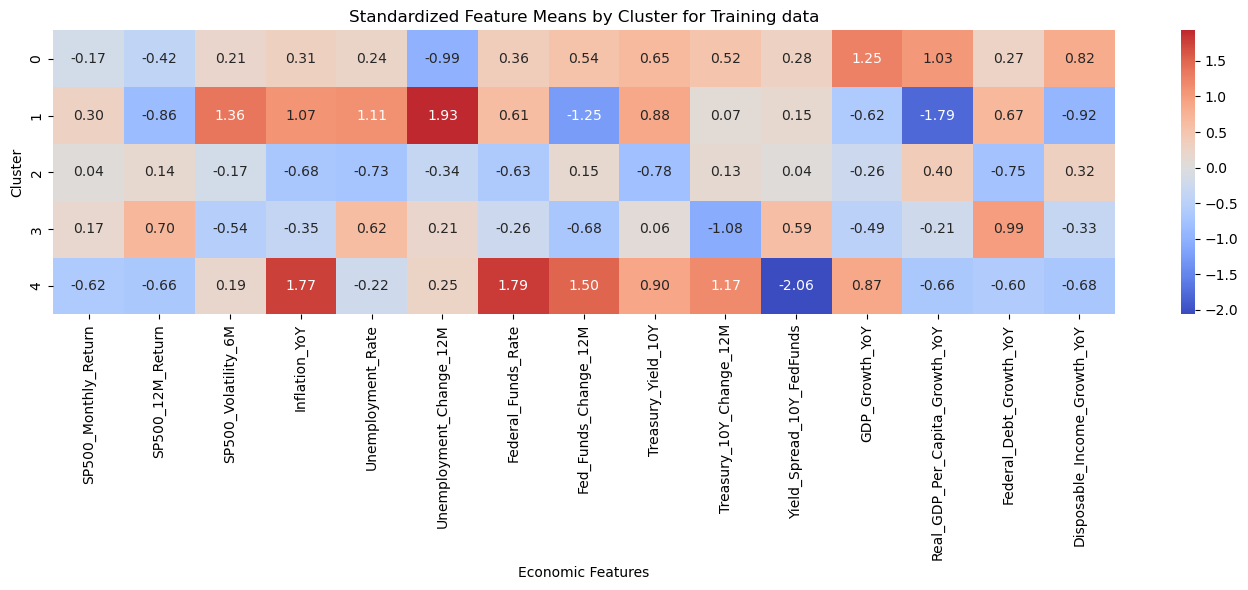

In [2172]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    cluster_heatmap,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Standardized Feature Means by Cluster for Training data")
plt.xlabel("Economic Features")
plt.ylabel("Cluster")

plt.tight_layout()

# Save chart for README
plt.savefig("images/kmeans_regime_profiles.png", dpi=300, bbox_inches="tight")

plt.show()

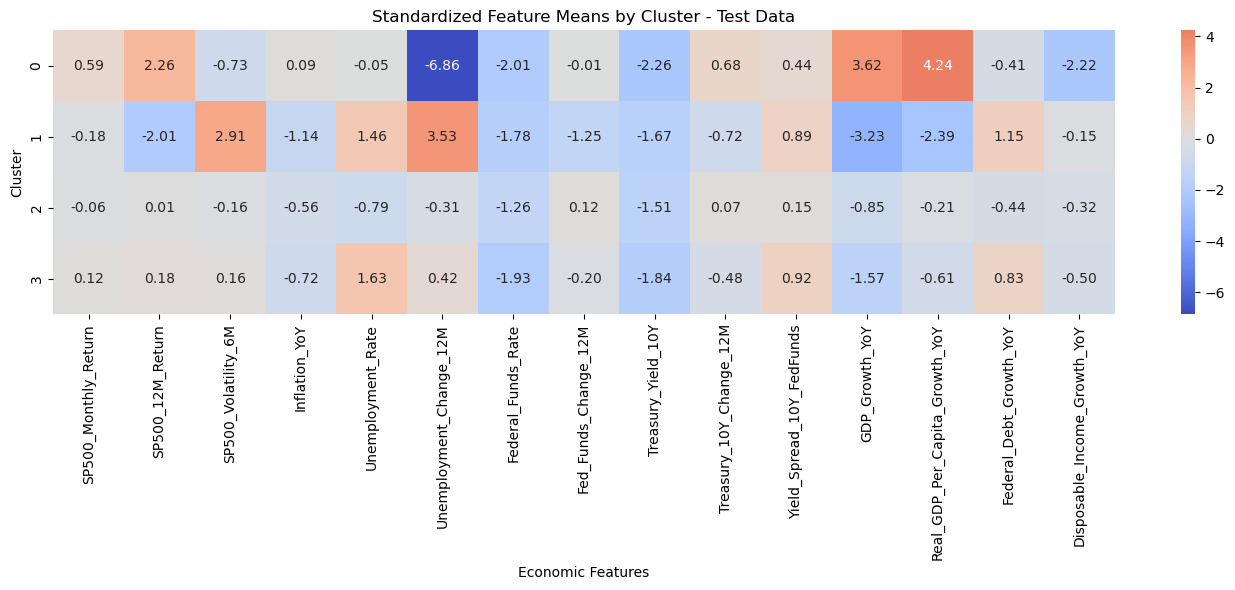

In [2173]:
# Add cluster labels to standardized test data
test_scaled_with_clusters = test_scaled.copy()
test_scaled_with_clusters["Cluster"] = test_clusters

test_cluster_heatmap = test_scaled_with_clusters.groupby("Cluster").mean() # Calculate average standardized features by cluster

# Create heatmap
plt.figure(figsize=(14, 6))

sns.heatmap(
    test_cluster_heatmap,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Standardized Feature Means by Cluster - Test Data")
plt.xlabel("Economic Features")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

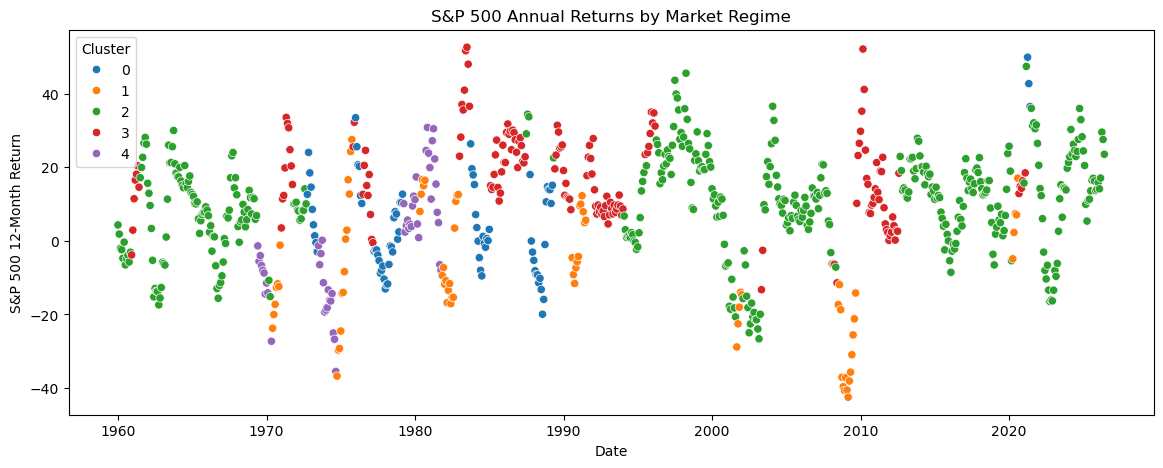

In [2174]:
plt.figure(figsize=(14, 5))

sns.scatterplot(
    data=ml_data,
    x="Date",
    y="SP500_12M_Return",
    hue="Cluster",
    palette="tab10"
)

plt.title("S&P 500 Annual Returns by Market Regime")
plt.xlabel("Date")
plt.ylabel("S&P 500 12-Month Return")

plt.show()

### Initial Interpretation of the Clusters

Based on their average economic characteristics, the five K-Means clusters were interpreted as:

- **Cluster 0 – Moderate Growth:** Moderate inflation, positive economic growth, and modest stock returns.
- **Cluster 1 – Market Stress:** Negative stock returns, high volatility, elevated unemployment, and weaker growth.
- **Cluster 2 – Stable Growth:** Lower inflation, lower unemployment, and positive stock returns.
- **Cluster 3 – Market Recovery:** Improving stock returns alongside relatively high unemployment.
- **Cluster 4 – High Inflation / Monetary Tightening:** High inflation, elevated interest rates, and tighter monetary conditions.

These labels are interpretations of the cluster profiles rather than predefined economic categories.

## 12. Historical Analysis of the Identified Regimes

After identifying five clusters using K-Means, the cluster assignments were examined over time and compared with historical economic periods and NBER recession dates. The goal is to assess whether the identified groups reflect recognizable economic and financial market conditions.



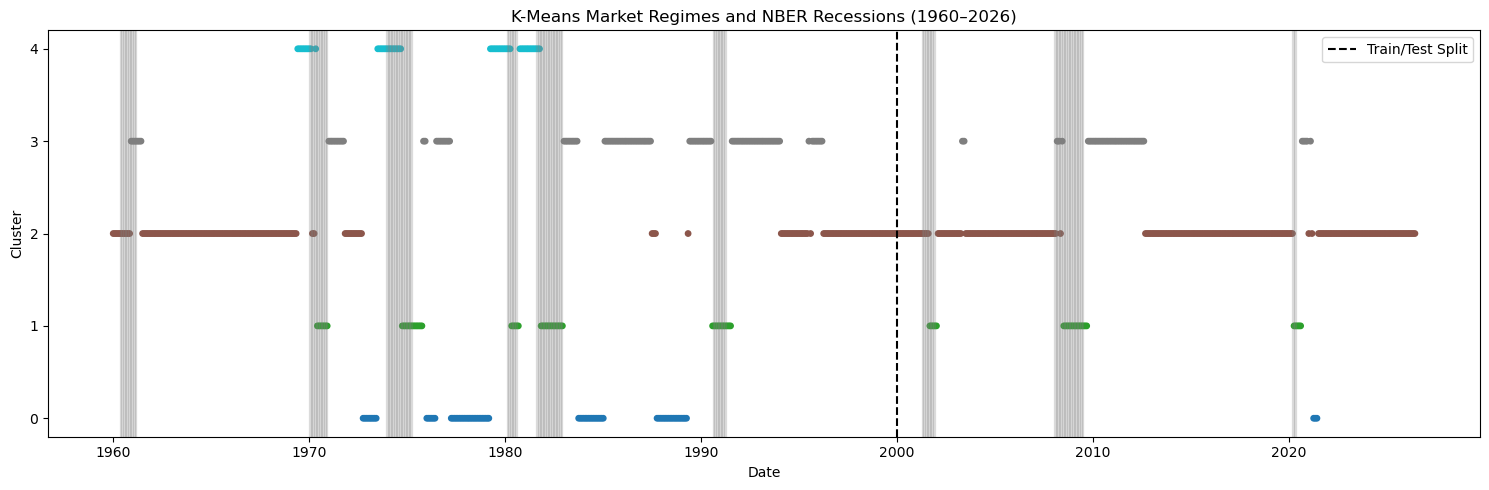

In [2175]:
# Plot K-Means clusters over time
plt.figure(figsize=(15, 5))

plt.scatter(
    ml_data["Date"],
    ml_data["Cluster"],
    c=ml_data["Cluster"],
    cmap="tab10",
    s=15
)

# Shade NBER recession months
for i in ml_data.index:
    if ml_data.loc[i, "NBER_Recession"] == 1:
        plt.axvspan(
            ml_data.loc[i, "Date"],
            ml_data.loc[i, "Date"] + pd.DateOffset(months=1),
            color="gray",
            alpha=0.2
        )

# Mark the training/testing split
plt.axvline(
    pd.Timestamp("2000-01-01"),
    color="black",
    linestyle="--",
    label="Train/Test Split"
)

plt.title("K-Means Market Regimes and NBER Recessions (1960–2026)")
plt.xlabel("Date")
plt.ylabel("Cluster")
plt.yticks(range(5))
plt.legend()
plt.tight_layout()

# Save chart for README
plt.savefig("images/historical_regimes.png", dpi=300, bbox_inches="tight")

plt.show()

### Comparison with Historical Economic Conditions

The distribution of clusters was examined across selected recessions, recoveries, inflationary periods, and expansions.

In [2176]:
# Important historical periods for comparison
historical_periods = {
    "1960-61 Recession": ("1960-04-01", "1961-02-01"),
    "1962-65 Expansion": ("1962-01-01", "1965-12-01"),
    "1966-69 Late Expansion": ("1966-01-01", "1969-11-01"),
    "1970 Recession": ("1969-12-01", "1970-11-01"),
    "1971-72 Recovery": ("1971-01-01", "1972-12-01"),
    "1973-75 Oil Shock/Recession": ("1973-11-01", "1975-03-01"),
    "1976-78 Recovery/Inflation": ("1976-01-01", "1978-12-01"),
    "1979-80 Inflation/Tightening/Recession": ("1979-01-01", "1980-12-01"),
    "1981-82 Recession": ("1981-07-01", "1982-11-01"),
    "1983-86 Recovery": ("1983-01-01", "1986-12-01"),
    "1987-89 Expansion": ("1987-01-01", "1989-12-01"),
    "1990-91 Recession": ("1990-07-01", "1991-03-01"),
    "1992-95 Expansion": ("1992-01-01", "1995-12-01"),
    "1996-99 Strong Expansion": ("1996-01-01", "1999-12-01"),
    "2000-02 Dot-Com Bust/Recession Era": ("2000-01-01", "2002-12-01"),
    "2003-06 Expansion": ("2003-01-01", "2006-12-01"),
    "2007 Pre-Crisis": ("2007-01-01", "2007-11-01"),
    "2007-09 Great Recession": ("2007-12-01", "2009-06-01"),
    "2009-12 Early Recovery": ("2009-07-01", "2012-12-01"),
    "2013-15 Expansion": ("2013-01-01", "2015-12-01"),
    "2016-19 Expansion": ("2016-01-01", "2019-12-01"),
    "2020 COVID Recession": ("2020-02-01", "2020-04-01"),
    "2020-21 Recovery": ("2020-05-01", "2021-12-01"),
    "2022-23 Inflation/Tightening": ("2022-01-01", "2023-12-01"),
    "2024-26 Recent Period": ("2024-01-01", "2026-06-01")
}

### Historical Periods Used for Comparison

Sources:
- NBER: U.S. Business Cycle Expansions and Contractions
- Federal Reserve History: The Great Inflation and The Great Moderation

In [2177]:
# Compare cluster distribution across historical periods
historical_results = []

for period, (start, end) in historical_periods.items():

    period_data = ml_data[
        (ml_data["Date"] >= start) &
        (ml_data["Date"] <= end)
    ]

    percentages = (
        period_data["Cluster"]
        .value_counts(normalize=True) * 100
    )

    historical_results.append([
        period,
        *[percentages.get(k, 0) for k in range(5)]
    ])

historical_results = pd.DataFrame(
    historical_results,
    columns=["Period"] + [f"Cluster {k}" for k in range(5)]
)

display(historical_results.round(1))

,Period,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4
0,1960-61 Recession,0.0,0.0,72.7,27.3,0.0
1,1962-65 Expansion,0.0,0.0,100.0,0.0,0.0
2,1966-69 Late Expansion,0.0,0.0,87.2,0.0,12.8
3,1970 Recession,0.0,50.0,16.7,0.0,33.3
4,1971-72 Recovery,12.5,0.0,45.8,41.7,0.0
5,1973-75 Oil Shock/Recession,0.0,35.3,0.0,0.0,64.7
6,1976-78 Recovery/Inflation,75.0,0.0,0.0,25.0,0.0
7,1979-80 Inflation/Tightening/Recession,12.5,20.8,0.0,0.0,66.7
8,1981-82 Recession,0.0,76.5,0.0,0.0,23.5
9,1983-86 Recovery,33.3,0.0,0.0,66.7,0.0


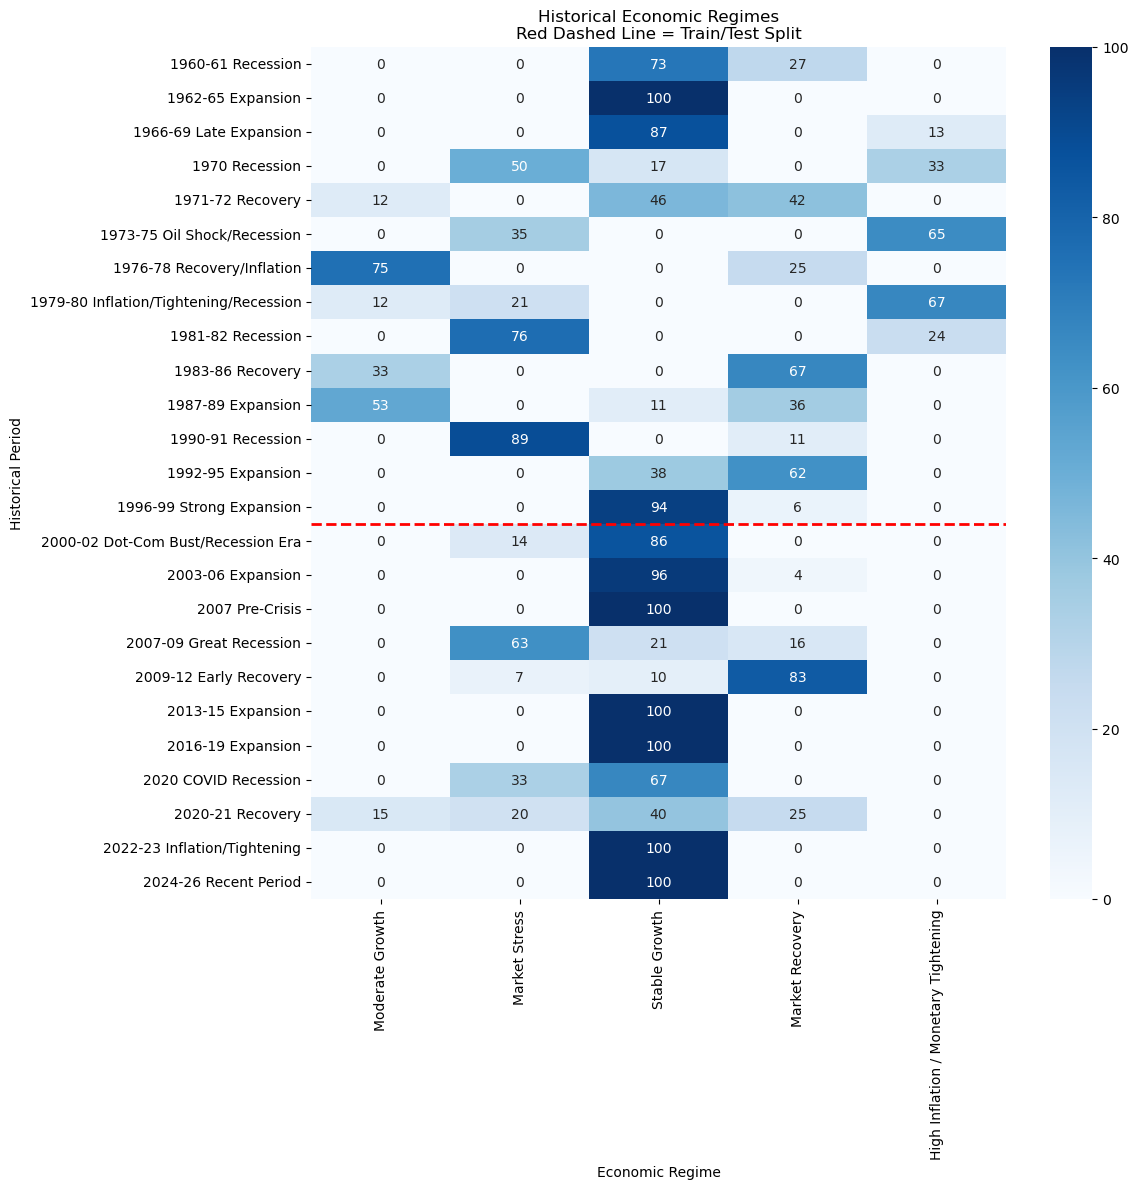

In [2178]:
# Use historical periods as row labels
history_heatmap = historical_results.set_index("Period")

# Names based on the five cluster profiles
cluster_names = {
    "Cluster 0": "Moderate Growth",
    "Cluster 1": "Market Stress",
    "Cluster 2": "Stable Growth",
    "Cluster 3": "Market Recovery",
    "Cluster 4": "High Inflation / Monetary Tightening"
}

history_heatmap = history_heatmap.rename(columns=cluster_names)

# Plot historical cluster distribution
plt.figure(figsize=(12, 12))

sns.heatmap(
    history_heatmap,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

# Separate training and testing periods
plt.axhline(y=14, color="red", linestyle="--", linewidth=2)

plt.title("Historical Economic Regimes\nRed Dashed Line = Train/Test Split")
plt.xlabel("Economic Regime")
plt.ylabel("Historical Period")

plt.tight_layout()
plt.show()

### Historical Comparison - Key Findings

The heatmap shows the percentage of months assigned to each regime during selected historical periods. The red dashed line separates the training and testing periods.

Market Stress appeared frequently during major recessions, while High Inflation / Monetary Tightening was common during inflationary periods in the 1970s and early 1980s. Market Recovery was associated with several recovery periods, and Stable Growth was common during expansions.

However, all months in the 2022–2023 inflation/tightening period were classified as Stable Growth rather than High Inflation. This shows that the clusters capture some historical patterns, but their economic interpretation does not always remain consistent over time.

## 13. Regime Transition

This section examines how often the five economic regimes changed from one month to the next and how long each regime typically lasted. The analysis uses the training period (1960–1999).

In [2179]:
# Use training data to study regime transitions
regime_data = train_data.sort_values("Date").copy()

# Identify the following month's cluster
regime_data["Next_Cluster"] = regime_data["Cluster"].shift(-1)

# Count transitions between the five clusters
transition_counts = pd.crosstab(
    regime_data["Cluster"],
    regime_data["Next_Cluster"]
)

# Calculate transition percentages
transition_pct = transition_counts.div(
    transition_counts.sum(axis=1), axis=0
) * 100

# Display all five clusters
transition_pct = transition_pct.reindex(
    index=range(5),
    columns=range(5),
    fill_value=0
)

display(transition_pct.round(1))

Next_Cluster,0,1,2,3,4
Cluster,,,,,
0,93.2,0.0,1.4,2.7,2.7
1,0.0,90.2,0.0,7.8,2.0
2,1.1,0.0,95.7,2.2,1.1
3,2.5,0.8,5.1,91.5,0.0
4,0.0,7.8,2.0,0.0,90.2


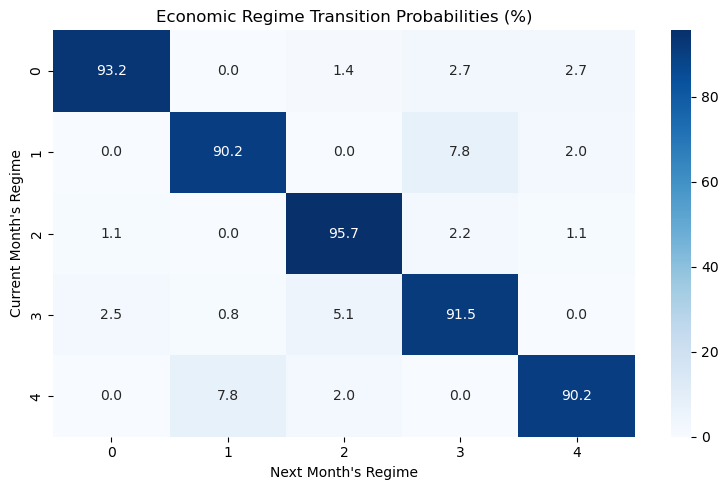

In [2180]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    transition_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Economic Regime Transition Probabilities (%)")
plt.xlabel("Next Month's Regime")
plt.ylabel("Current Month's Regime")
plt.tight_layout()
plt.show()

### Regime Transition Interpretation

The transition matrix shows that all five regimes have a probability of at least 90% of remaining in the same regime in the following month. Stable Growth has the highest persistence (95.7%), followed by Moderate Growth (93.2%) and Market Recovery (91.5%). Market Stress and High Inflation / Monetary Tightening both have persistence rates of 90.2%. The clusters tend to remain unchanged for several consecutive months.

## 14. Gaussian Mixture Model (GMM)

Gaussian Mixture Model (GMM) was used to compare its results with K-Means clustering. Unlike K-Means, GMM allows clusters to have different shapes and estimates the probability of each observation belonging to a cluster. The model was fitted on the six PCA components from the training period (1960–1999) and applied to the test period (2000–2026).

In [2181]:
# Compare GMM models using BIC and AIC
gmm_results = []

for k in range(2, 21):
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=5
    )

    gmm.fit(train_pca)

    gmm_results.append([
        k,
        gmm.bic(train_pca),
        gmm.aic(train_pca)
    ])

# Display results
gmm_results = pd.DataFrame(
    gmm_results,
    columns=["Number_of_Clusters", "BIC", "AIC"]
)

display(gmm_results.round(2))

,Number_of_Clusters,BIC,AIC
0,2,9439.80,9210.25
1,3,9325.40,8978.97
2,4,9219.70,8756.41
3,5,9176.15,8595.99
4,6,9199.32,8502.30
5,7,9165.54,8351.66
6,8,9066.64,8135.89
7,9,9145.52,8097.90
8,10,9148.36,7983.88
9,11,8987.17,7705.82


### GMM Model Selection

Models with 2–20 components were compared using BIC and AIC. BIC was lowest at 11 components, while AIC favored 20 components. Cluster sizes and economic profiles were also examined before selecting the final model.

In [2182]:
# Compare cluster sizes for selected GMM models
gmm_labels = {}

for k in [5, 8, 11]:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=5
    )

    labels = gmm.fit_predict(train_pca)
    gmm_labels[k] = labels

    print(f"\n{k} Components:")
    print(pd.Series(labels).value_counts().sort_index())


5 Components:
0     67
1    105
2    108
3    133
4     67
Name: count, dtype: int64

8 Components:
0    35
1    32
2    51
3    58
4    52
5    68
6    93
7    91
Name: count, dtype: int64

11 Components:
0     85
1     53
2     29
3     11
4     52
5     56
6     37
7     30
8     21
9     49
10    57
Name: count, dtype: int64


In [2183]:
# Compare economic profiles for 5 and 8 GMM components
for k in [5, 8]:
    profiles = train_data[key_features].copy()
    profiles["Cluster"] = gmm_labels[k]

    print(f"\n{k} GMM Components - Economic Profiles:")
    display(profiles.groupby("Cluster")[key_features].mean().round(2))


5 GMM Components - Economic Profiles:


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,5.96,4.24,7.01,8.01,1.26,6.51
1,0.21,3.44,7.16,5.17,-1.29,9.75
2,12.75,2.52,1.68,4.97,0.72,6.23
3,17.54,2.16,3.24,6.04,1.48,6.26
4,4.50,3.07,4.86,6.93,2.09,10.15



8 GMM Components - Economic Profiles:


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,25.40,3.49,2.15,4.79,0.57,5.99
1,5.00,3.16,11.64,6.49,-3.07,10.75
2,2.33,3.08,5.62,6.63,1.43,11.33
3,20.21,2.45,3.94,7.48,1.94,8.34
4,-1.86,4.67,7.66,7.72,1.12,5.88
5,-3.29,3.84,4.81,4.45,-0.45,8.59
6,15.49,1.95,3.40,6.16,1.62,6.05
7,10.68,2.23,1.70,5.06,0.87,6.35


### Final GMM Component Selection

After comparing BIC, AIC, cluster sizes, and economic profiles, eight components were selected for the final GMM model. Although BIC favored 11 components, the eight-component model produced reasonably sized groups and captured different economic conditions. The five-component model was simpler but did not clearly separate negative stock market conditions.

In [2184]:
# Fit final GMM on training PCA components
gmm_final = GaussianMixture(
    n_components=8,
    covariance_type="full",
    random_state=42,
    n_init=5
)

train_gmm_clusters = gmm_final.fit_predict(train_pca)

# Assign testing observations using the trained model
test_gmm_clusters = gmm_final.predict(test_pca)

# Check cluster distribution
print("Training clusters:")
print(pd.Series(train_gmm_clusters).value_counts().sort_index())

print("\nTesting clusters:")
print(pd.Series(test_gmm_clusters).value_counts().sort_index())

Training clusters:
0    35
1    32
2    51
3    58
4    52
5    68
6    93
7    91
Name: count, dtype: int64

Testing clusters:
0      1
1      5
2     11
3      8
4    116
5     72
6     64
7     41
Name: count, dtype: int64


In [2185]:
# Compare GMM economic profiles in the testing period
gmm_test_profiles = test_data[key_features].copy()
gmm_test_profiles["Cluster"] = test_gmm_clusters

display(
    gmm_test_profiles.groupby("Cluster")[key_features]
    .mean()
    .round(2)
)

,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
0,2.74,2.69,3.36,5.20,1.55,6.69
1,-15.12,6.62,1.78,6.80,1.98,3.19
2,9.25,4.63,2.62,5.46,1.09,5.03
3,19.82,2.47,3.59,4.40,0.60,9.41
4,-0.79,3.98,2.64,5.95,1.51,3.25
5,8.58,2.80,2.56,4.29,0.54,5.37
6,18.27,2.12,2.43,6.78,2.10,5.14
7,14.05,1.99,2.68,5.33,0.90,5.61


In [2186]:
# Compare GMM clusters with NBER recession months
gmm_recession = test_data[["NBER_Recession"]].copy()
gmm_recession["Cluster"] = test_gmm_clusters

gmm_recession_summary = gmm_recession.groupby("Cluster")["NBER_Recession"].agg(
    Total_Months="count",
    Recession_Months="sum",
    Recession_Rate="mean"
)

gmm_recession_summary["Recession_Rate"] *= 100

display(gmm_recession_summary.round(1))

,Total_Months,Recession_Months,Recession_Rate
Cluster,,,
0,1,0,0.0
1,5,4,80.0
2,11,1,9.1
3,8,0,0.0
4,116,23,19.8
5,72,0,0.0
6,64,0,0.0
7,41,0,0.0


### GMM Interpretation

GMM identified several economic patterns, but some components had similar characteristics, making it difficult to interpret all eight as separate economic regimes. GMM was mainly used as an alternative clustering method to compare with K-Means, rather than assigning a separate economic regime name to every component.

## 15. DBSCAN Clustering

DBSCAN was used as a third clustering method to identify groups of similar economic conditions. Unlike K-Means and GMM, DBSCAN does not require a predefined number of clusters. The model was applied to the six PCA components from the training period (1960–1999).

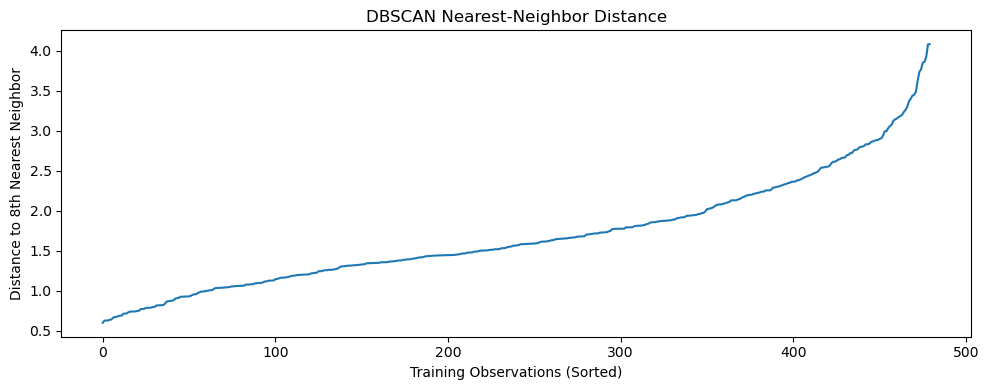

In [2187]:
# Calculate distances to the 8th nearest neighbor
neighbors = NearestNeighbors(n_neighbors=8)
neighbors.fit(train_pca)

distances = neighbors.kneighbors(train_pca)[0]
k_distances = np.sort(distances[:, -1])

# Plot nearest-neighbor distances
plt.figure(figsize=(10, 4))
plt.plot(k_distances)

plt.title("DBSCAN Nearest-Neighbor Distance")
plt.xlabel("Training Observations (Sorted)")
plt.ylabel("Distance to 8th Nearest Neighbor")

plt.tight_layout()
plt.show()


In [2188]:
# Compare DBSCAN parameters
results = []

for min_samples in [6, 8, 12]:
    for eps in [1.5, 2.0, 2.5]:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(train_pca)

        n_clusters = len(set(labels) - {-1})
        noise_months = sum(labels == -1)

        results.append([min_samples, eps, n_clusters, noise_months])

dbscan_results = pd.DataFrame(
    results,
    columns=["min_samples", "eps", "Clusters", "Noise_Months"]
)

display(dbscan_results)


,min_samples,eps,Clusters,Noise_Months
0,6,1.5,6,121
1,6,2.0,1,64
2,6,2.5,1,16
3,8,1.5,2,171
4,8,2.0,3,77
5,8,2.5,1,22
6,12,1.5,2,227
7,12,2.0,1,115
8,12,2.5,1,39


In [2189]:
# Examine DBSCAN cluster sizes
dbscan = DBSCAN(eps=2.0, min_samples=8)
dbscan_labels = dbscan.fit_predict(train_pca)

print("Cluster sizes:")
print(pd.Series(dbscan_labels).value_counts().sort_index())


Cluster sizes:
-1     77
 0    378
 1     16
 2      9
Name: count, dtype: int64


In [2190]:

# Compare economic characteristics of DBSCAN groups
dbscan_profiles = train_data[key_features].copy()
dbscan_profiles["Cluster"] = dbscan_labels

display(
    dbscan_profiles.groupby("Cluster")[key_features]
    .mean()
    .round(2)
)


,SP500_12M_Return,SP500_Volatility_6M,Inflation_YoY,Unemployment_Rate,Yield_Spread_10Y_FedFunds,GDP_Growth_YoY
Cluster,,,,,,
-1,1.28,4.45,8.37,7.41,-0.55,8.31
0,11.52,2.58,3.66,5.67,0.96,7.48
1,-3.77,4.45,5.74,6.30,1.34,4.40
2,4.61,2.27,4.26,7.80,2.39,11.93


### DBSCAN Interpretation

Using eps = 2.0 and min_samples = 8, DBSCAN identified three clusters and 77 noise observations. Most observations (378 out of 480) belonged to one large cluster, suggesting that DBSCAN did not separate the data into several balanced economic regimes.

The noise observations showed higher inflation, unemployment, and market volatility, along with weaker stock returns compared with the main cluster. DBSCAN therefore appears more useful for identifying unusual economic conditions than for defining distinct market regimes.

In [2191]:
# Compare DBSCAN noise with NBER recessions
dbscan_recession = train_data[["NBER_Recession"]].copy()
dbscan_recession["Cluster"] = dbscan_labels

summary = dbscan_recession.groupby("Cluster")["NBER_Recession"].agg(
    Total_Months="count",
    Recession_Months="sum",
    Recession_Rate="mean"
)

summary["Recession_Rate"] *= 100

display(summary.round(1))


,Total_Months,Recession_Months,Recession_Rate
Cluster,,,
-1,77,39,50.6
0,378,17,4.5
1,16,11,68.8
2,9,0,0.0


### DBSCAN Recession Alignment

DBSCAN groups were compared with NBER recession months during the training period. The noise group contained 77 months, including 39 recession months (50.6%). Cluster 1 had a recession rate of 68.8%, while the main Cluster 0 had a recession rate of only 4.5%. Together, the noise group and Cluster 1 contained 50 of the 67 recession months.

These findings suggest that DBSCAN can identify unusual conditions associated with historical recessions, although its clusters are less suitable for describing different economic regimes.

## 16. Comparison of Clustering Methods

K-Means, GMM, and DBSCAN were compared based on their cluster structures, economic interpretation, and relationship with historical recessions. Since the algorithms work differently, the comparison focuses on their usefulness for identifying economic regimes rather than expecting identical clustering results.

### Comparison of K-Means, GMM, and DBSCAN

| Criteria | K-Means | GMM | DBSCAN |
|---|---|---|---|
| Selected model | 5 clusters | 8 components | eps = 2.0, min_samples = 8 |
| Number of groups | 5 | 8 | 3 clusters + noise |
| Economic interpretation | Five distinct economic profiles | More detailed but overlapping economic patterns | One dominant cluster and unusual observations |
| Testing-period results | Only 4 of 5 clusters appeared | All 8 components appeared, with uneven frequencies | Not evaluated on testing data |
| Main strength | Clearer economic interpretation | Flexible clustering structure | Identifies unusual economic conditions |
| Main limitation | Some regimes do not appear in testing | More difficult to interpret | Does not identify several balanced regimes |

### Interpretation of Clustering Results

**K-Means:** The five-cluster model provided the clearest economic interpretation, identifying conditions such as stable growth, market recovery, market stress, and high inflation. However, one cluster did not appear in the test period.

**GMM:** The eight-component model identified more detailed patterns, but some components had similar characteristics and were difficult to interpret as separate economic regimes.

**DBSCAN:** Most observations belonged to one large cluster, while 77 months were classified as noise. These unusual observations were more frequently associated with historical recessions.

K-Means was the preferred method for interpreting economic regimes in this project. These findings describe historical patterns rather than predicting future recessions.

## 17. Supervised Learning - NBER Recession Classification

After identifying economic regimes using unsupervised learning, supervised learning was used to classify historical U.S. recession and non-recession months using the NBER recession indicator.

The target variable is:
- **1:** Recession
- **0:** Non-recession

Unlike the earlier clustering analysis, the recession labels are independently defined by NBER. Four classification models were compared using the original 15 economic and financial features:

- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)

The models were trained on data from 1960–1999 and evaluated on the 2000–2026 testing period.

In [2192]:
# Define supervised learning features and target
X_train = train_data[model_features].copy()
X_test = test_data[model_features].copy()

y_train = train_data["NBER_Recession"]
y_test = test_data["NBER_Recession"]

# Check dataset sizes and recession labels
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (480, 15)
Testing features: (318, 15)

Training target distribution:
NBER_Recession
0    413
1     67
Name: count, dtype: int64

Testing target distribution:
NBER_Recession
0    290
1     28
Name: count, dtype: int64


### Logistic Regression Baseline Model

Logistic Regression was used to classify recession and non-recession months. Since recession months are less common, balanced class weights were applied. StandardScaler was included in the pipeline to standardize features using training data only.

In [2193]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Fit using training data only
logistic_model.fit(X_train, y_train)

# Predict recession labels for testing data
logistic_predictions = logistic_model.predict(X_test)

print("Predicted recession months:", sum(logistic_predictions))
print("Actual recession months:", sum(y_test))


Predicted recession months: 56
Actual recession months: 28


In [2194]:
# Evaluate Logistic Regression predictions
print("Confusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions, zero_division=0))

Confusion Matrix:
[[257  33]
 [  5  23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.89      0.93       290
           1       0.41      0.82      0.55        28

    accuracy                           0.88       318
   macro avg       0.70      0.85      0.74       318
weighted avg       0.93      0.88      0.90       318



### Logistic Regression Initial Test Results

Logistic Regression correctly identified 23 of the 28 recession months, achieving 82% recall for recession. However, it also incorrectly classified 33 non-recession months as recessions. This resulted in 41% precision and a recession F1-score of 0.55.

The model identified most recession months but generated several false positives.

In [2195]:
tscv = TimeSeriesSplit(n_splits=5)

cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=tscv,
    scoring={
        "Precision": make_scorer(precision_score, zero_division=0),
        "Recall": make_scorer(recall_score, zero_division=0),
        "F1": make_scorer(f1_score, zero_division=0)
    }
)

print("Average CV Precision:", round(cv_results["test_Precision"].mean(), 2))
print("Average CV Recall:", round(cv_results["test_Recall"].mean(), 2))
print("Average CV F1:", round(cv_results["test_F1"].mean(), 2))


Average CV Precision: 0.5
Average CV Recall: 0.71
Average CV F1: 0.52


### Decision Tree Classification

A Decision Tree was used to capture possible nonlinear relationships between economic indicators. The tree depth and minimum leaf size were adjusted to reduce overfitting, while balanced class weights were used to account for fewer recession observations.

In [2196]:
# Build Decision Tree model

tree_model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Predict on testing data
tree_predictions = tree_model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, tree_predictions))

print("\nClassification Report:")
print(classification_report(y_test, tree_predictions, zero_division=0))

Confusion Matrix:
[[250  40]
 [  1  27]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.86      0.92       290
           1       0.40      0.96      0.57        28

    accuracy                           0.87       318
   macro avg       0.70      0.91      0.75       318
weighted avg       0.94      0.87      0.89       318



### Decision Tree Initial Test Results

The Decision Tree correctly identified 27 of the 28 recession months, achieving 96% recall. However, it incorrectly classified 40 non-recession months as recessions, resulting in 40% precision. Its recession F1-score was 0.57, slightly higher than Logistic Regression (0.55), but it generated more false positives.

In [2197]:
# Decision Tree - Time Series Cross-Validation
tree_cv = cross_validate(
    tree_model,
    X_train,
    y_train,
    cv=tscv,
    scoring={
        "Precision": make_scorer(precision_score, zero_division=0),
        "Recall": make_scorer(recall_score, zero_division=0),
        "F1": make_scorer(f1_score, zero_division=0)
    }
)

print("Average CV Precision:", round(tree_cv["test_Precision"].mean(), 2))
print("Average CV Recall:", round(tree_cv["test_Recall"].mean(), 2))
print("Average CV F1:", round(tree_cv["test_F1"].mean(), 2))


Average CV Precision: 0.44
Average CV Recall: 0.45
Average CV F1: 0.42


### Random Forest Classification

Random Forest was used to combine multiple Decision Trees and capture nonlinear relationships between economic indicators.

The model used balanced class weights and the same training and testing periods as the other classifiers.

In [2198]:
# Build and evaluate Random Forest

forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, forest_predictions))

print("\nClassification Report:")
print(classification_report(y_test, forest_predictions, zero_division=0))

Confusion Matrix:
[[263  27]
 [  0  28]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95       290
           1       0.51      1.00      0.67        28

    accuracy                           0.92       318
   macro avg       0.75      0.95      0.81       318
weighted avg       0.96      0.92      0.93       318



### Random Forest Initial Test Results

Random Forest correctly identified all 28 recession months, achieving 100% recall. It incorrectly classified 27 non-recession months as recessions, resulting in 51% precision. The recession F1-score was 0.67, making Random Forest the strongest of the initial models on the testing data.

In [2199]:
# Random Forest - Time Series Cross-Validation
forest_cv = cross_validate(
    forest_model,
    X_train,
    y_train,
    cv=tscv,
    scoring={
        "Precision": make_scorer(precision_score, zero_division=0),
        "Recall": make_scorer(recall_score, zero_division=0),
        "F1": make_scorer(f1_score, zero_division=0)
    }
)

print("Average CV Precision:", round(forest_cv["test_Precision"].mean(), 2))
print("Average CV Recall:", round(forest_cv["test_Recall"].mean(), 2))
print("Average CV F1:", round(forest_cv["test_F1"].mean(), 2))


Average CV Precision: 0.5
Average CV Recall: 0.59
Average CV F1: 0.5


### K-Nearest Neighbors (KNN) Classification

KNN was used to classify months based on similarities in their economic and financial indicators. Since KNN relies on distances between observations, StandardScaler was included in the pipeline. The initial model used seven nearest neighbors.

In [2200]:
# Build KNN model
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=7)
)

# Train the model
knn_model.fit(X_train, y_train)

# Predict on testing data
knn_predictions = knn_model.predict(X_test)

# Evaluate KNN
print("Confusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))

print("\nClassification Report:")
print(classification_report(y_test, knn_predictions, zero_division=0))


Confusion Matrix:
[[263  27]
 [  5  23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.91      0.94       290
           1       0.46      0.82      0.59        28

    accuracy                           0.90       318
   macro avg       0.72      0.86      0.77       318
weighted avg       0.94      0.90      0.91       318



### KNN Initial Test Results

KNN correctly identified 23 of the 28 recession months, achieving 82% recall. It incorrectly classified 27 non-recession months as recessions, resulting in 46% precision. The recession F1-score was 0.59, higher than Logistic Regression but lower than Random Forest.

In [2201]:
# KNN - Time Series Cross-Validation
knn_cv = cross_validate(
    knn_model,
    X_train,
    y_train,
    cv=tscv,
    scoring={
        "Precision": make_scorer(precision_score, zero_division=0),
        "Recall": make_scorer(recall_score, zero_division=0),
        "F1": make_scorer(f1_score, zero_division=0)
    }
)

print("Average CV Precision:", round(knn_cv["test_Precision"].mean(), 2))
print("Average CV Recall:", round(knn_cv["test_Recall"].mean(), 2))
print("Average CV F1:", round(knn_cv["test_F1"].mean(), 2))

Average CV Precision: 0.49
Average CV Recall: 0.31
Average CV F1: 0.32


In [2202]:
# Compare supervised models on testing data
models = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions,
    "KNN": knn_predictions
}

results = []

for name, predictions in models.items():
    results.append([
        name,
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions, zero_division=0),
        recall_score(y_test, predictions, zero_division=0),
        f1_score(y_test, predictions, zero_division=0)
    ])

model_comparison = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

display(model_comparison.round(2))


,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.88,0.41,0.82,0.55
1,Decision Tree,0.87,0.40,0.96,0.57
2,Random Forest,0.92,0.51,1.00,0.67
3,KNN,0.90,0.46,0.82,0.59


### Additional Nonlinear Feature Engineering

Interaction features were tested to determine whether they could improve recession classification.

Two additional features were created:

- **Inflation × Federal Funds Rate:** Interaction between inflation and monetary policy.
- **Yield Spread × Unemployment Rate:** Interaction between interest-rate conditions and unemployment.

The original 15 features were compared with the expanded set of 17 features using chronological cross-validation.

In [2203]:
# Create nonlinear feature datasets
X_train_nonlinear = X_train.copy()
X_test_nonlinear = X_test.copy()

for data in [X_train_nonlinear, X_test_nonlinear]:

    data["Inflation_FedFunds"] = (
        data["Inflation_YoY"] * data["Federal_Funds_Rate"]
    )

    data["YieldSpread_Unemployment"] = (
        data["Yield_Spread_10Y_FedFunds"] * data["Unemployment_Rate"]
    )

# Verify the number of observations and features
print("Training:", X_train_nonlinear.shape)
print("Testing:", X_test_nonlinear.shape)

Training: (480, 17)
Testing: (318, 17)


In [2204]:
# Compare original and nonlinear features using cross-validation

models_to_compare = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
    "KNN": knn_model
}

feature_sets = {
    "Original (15)": X_train,
    "Nonlinear (17)": X_train_nonlinear
}

comparison_results = []

for model_name, model in models_to_compare.items():
    for feature_name, X in feature_sets.items():

        scores = cross_validate(
            model, X, y_train,
            cv=tscv,
            scoring={
                "Precision": make_scorer(precision_score, zero_division=0),
                "Recall": make_scorer(recall_score, zero_division=0),
                "F1": make_scorer(f1_score, zero_division=0)
            }
        )

        comparison_results.append([
            model_name,
            feature_name,
            scores["test_Precision"].mean(),
            scores["test_Recall"].mean(),
            scores["test_F1"].mean(),
            scores["fit_time"].mean()
        ])

feature_comparison = pd.DataFrame(
    comparison_results,
    columns=["Model", "Features", "CV Precision",
             "CV Recall", "CV F1", "Avg Fit Time (sec)"]
)

display(feature_comparison.round(3))


,Model,Features,CV Precision,CV Recall,CV F1,Avg Fit Time (sec)
0,Logistic Regression,Original (15),0.499,0.706,0.523,0.011
1,Logistic Regression,Nonlinear (17),0.492,0.718,0.523,0.008
2,Decision Tree,Original (15),0.445,0.447,0.425,0.004
3,Decision Tree,Nonlinear (17),0.445,0.447,0.425,0.004
4,Random Forest,Original (15),0.499,0.588,0.496,0.187
5,Random Forest,Nonlinear (17),0.485,0.538,0.471,0.167
6,KNN,Original (15),0.489,0.315,0.320,0.004
7,KNN,Nonlinear (17),0.443,0.311,0.319,0.004


### Original vs. Nonlinear Features Interpretation

The two additional interaction features did not improve cross-validation F1-scores. Logistic Regression and Decision Tree showed no improvement, while Random Forest and KNN performed slightly worse. Therefore, the original 15 features were retained for the final models.

One validation fold contained no recession months, which limits the interpretation of the average recession recall and F1-scores.

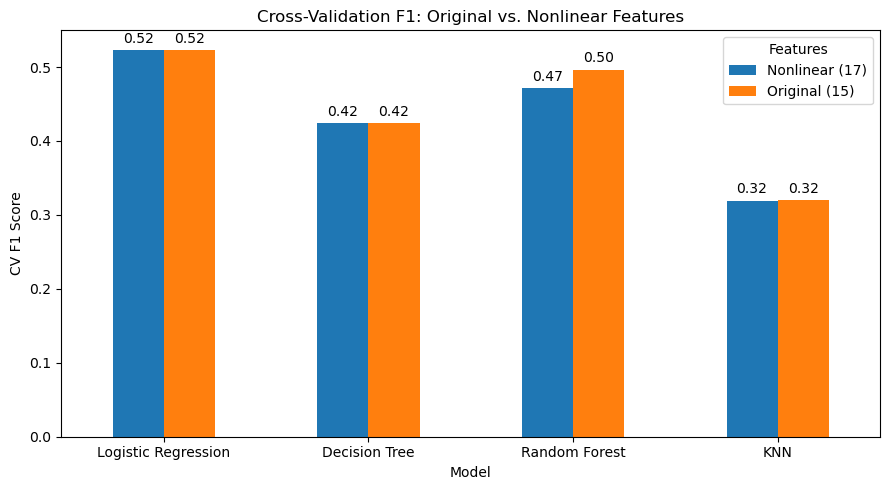

In [2205]:
# Compare CV F1 scores for original and nonlinear features
plot_data = feature_comparison.pivot(
    index="Model",
    columns="Features",
    values="CV F1"
)

plot_data = plot_data.reindex([
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "KNN"
])

# Create bar chart
ax = plot_data.plot(kind="bar", figsize=(9, 5))

# Display values above each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)

plt.title("Cross-Validation F1: Original vs. Nonlinear Features")
plt.xlabel("Model")
plt.ylabel("CV F1 Score")
plt.xticks(rotation=0)
plt.legend(title="Features")
plt.tight_layout()
plt.show()

## 18. Model Selection, Regularization, and Hyperparameter Tuning

This section uses TimeSeriesSplit and GridSearchCV to tune the four classification models. TimeSeriesSplit preserves the chronological order of the data. GridSearchCV compares different hyperparameter values and selects the combination with the highest average recession F1 score.

The tuning process included:

- **Logistic Regression:** L2 regularization strength.
- **Decision Tree:** Maximum depth and minimum leaf size.
- **Random Forest:** Maximum depth and minimum leaf size.
- **KNN:** Number of nearest neighbors.

Only the 1960–1999 training data was used for tuning. The 2000–2026 testing period was reserved for final evaluation.

In [2206]:
# Compare different regularization strengths
param_grid = {
    "logisticregression__C": [0.1, 1, 10, 100, 1000]
}

logistic_grid = GridSearchCV(
    logistic_model,
    param_grid,
    cv=tscv,
    scoring=make_scorer(f1_score, zero_division=0)
)

# Fit using training data only
logistic_grid.fit(X_train, y_train)

print("Best C:", logistic_grid.best_params_["logisticregression__C"])
print("Best CV F1:", round(logistic_grid.best_score_, 3))


Best C: 10
Best CV F1: 0.533


In [2207]:
# Tune Decision Tree
tree_params = {
    "max_depth": [1, 2, 3, 4, 5],
    "min_samples_leaf": [5, 10, 15]
}

tree_grid = GridSearchCV(
    tree_model,
    tree_params,
    cv=tscv,
    scoring=make_scorer(f1_score, zero_division=0)
)

tree_grid.fit(X_train, y_train)

print("Best parameters:", tree_grid.best_params_)
print("Best CV F1:", round(tree_grid.best_score_, 3))

Best parameters: {'max_depth': 2, 'min_samples_leaf': 10}
Best CV F1: 0.425


In [2208]:
# Tune Random Forest
forest_params = {
    "max_depth": [1, 2, 3, 4, 5],
    "min_samples_leaf": [5, 10, 15, 20, 25, 30]
}

forest_grid = GridSearchCV(
    forest_model,
    forest_params,
    cv=tscv,
    scoring=make_scorer(f1_score, zero_division=0),
    n_jobs=-1
)

forest_grid.fit(X_train, y_train)

print("Best parameters:", forest_grid.best_params_)
print("Best CV F1:", round(forest_grid.best_score_, 3))

Best parameters: {'max_depth': 2, 'min_samples_leaf': 15}
Best CV F1: 0.507


In [2209]:
# Tune KNN
knn_params = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15]
}

knn_grid = GridSearchCV(
    knn_model,
    knn_params,
    cv=tscv,
    scoring=make_scorer(f1_score, zero_division=0)
)

knn_grid.fit(X_train, y_train)

print("Best parameters:", knn_grid.best_params_)
print("Best CV F1:", round(knn_grid.best_score_, 3))


Best parameters: {'kneighborsclassifier__n_neighbors': 9}
Best CV F1: 0.331


In [2210]:
# Compare tuned models using cross-validation results

tuned_models = {
    "Logistic Regression": logistic_grid,
    "Decision Tree": tree_grid,
    "Random Forest": forest_grid,
    "KNN": knn_grid
}

results = []

for name, grid in tuned_models.items():
    results.append([
        name,
        round(grid.best_score_, 3),
        grid.best_params_
    ])

tuning_comparison = pd.DataFrame(
    results,
    columns=["Model", "Best CV F1", "Best Parameters"]
)

display(tuning_comparison.sort_values("Best CV F1", ascending=False))

,Model,Best CV F1,Best Parameters
0,Logistic Regression,0.533,{'logisticregression__C': 10}
2,Random Forest,0.507,"{'max_depth': 2, 'min_samples_leaf': 15}"
1,Decision Tree,0.425,"{'max_depth': 2, 'min_samples_leaf': 10}"
3,KNN,0.331,{'kneighborsclassifier__n_neighbors': 9}


### Hyperparameter Tuning Results

Logistic Regression achieved the highest cross-validation recession F1-score (0.533), followed by Random Forest (0.507), Decision Tree (0.425), and KNN (0.331).

Tuning produced small improvements for Logistic Regression, Random Forest, and KNN, while Decision Tree performance remained unchanged. Logistic Regression and Random Forest are the strongest candidates for final evaluation on the testing dataset.

In [2211]:
# Evaluate tuned models on testing data

test_results = []

for name, grid in tuned_models.items():

    predictions = grid.predict(X_test)

    test_results.append([
        name,
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions, zero_division=0),
        recall_score(y_test, predictions, zero_division=0),
        f1_score(y_test, predictions, zero_division=0)
    ])

tuned_test_comparison = pd.DataFrame(
    test_results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1"]
)

display(tuned_test_comparison.round(3))

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.884,0.415,0.786,0.543
1,Decision Tree,0.871,0.403,0.964,0.568
2,Random Forest,0.912,0.500,1.000,0.667
3,KNN,0.928,0.561,0.821,0.667


### Tuned Models Test Results

Random Forest and KNN achieved the highest recession F1-score (0.667) on the testing data. Random Forest identified all recession months but generated more false positives. KNN achieved higher precision and accuracy but missed some recession months.

Logistic Regression had the highest chronological cross-validation F1-score (0.533). Logistic Regression and Random Forest were retained for further interpretation because they showed the strongest cross-validation performance. KNN and Decision Tree were kept as comparison models.

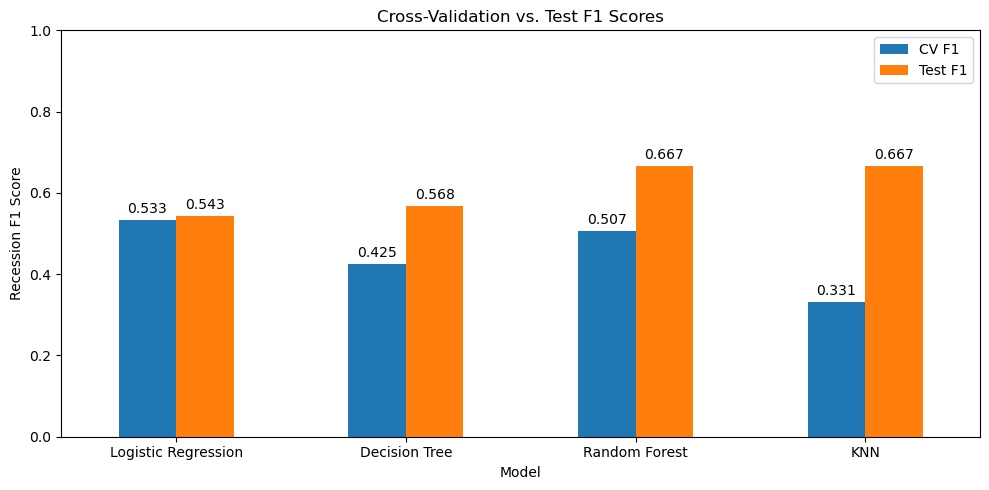

In [2212]:
# Prepare cross-validation and testing F1 scores
f1_comparison = pd.DataFrame({
    "Model": list(tuned_models.keys()),
    "CV F1": [grid.best_score_ for grid in tuned_models.values()]
})

f1_comparison = f1_comparison.merge(
    tuned_test_comparison[["Model", "F1"]],
    on="Model"
).rename(columns={"F1": "Test F1"})

# Create comparison chart
ax = f1_comparison.set_index("Model")[["CV F1", "Test F1"]].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

# Display values above each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)

plt.title("Cross-Validation vs. Test F1 Scores")
plt.xlabel("Model")
plt.ylabel("Recession F1 Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Cross-Validation vs. Test F1 - Interpretation

Logistic Regression had similar cross-validation and testing F1-scores (0.533 and 0.543). Random Forest improved from 0.507 in cross-validation to 0.667 in testing, while KNN showed the largest difference (0.331 vs. 0.667).

These differences show that classification performance varies across economic periods. Although Random Forest and KNN performed best on the testing data, Logistic Regression had the highest cross-validation F1-score.

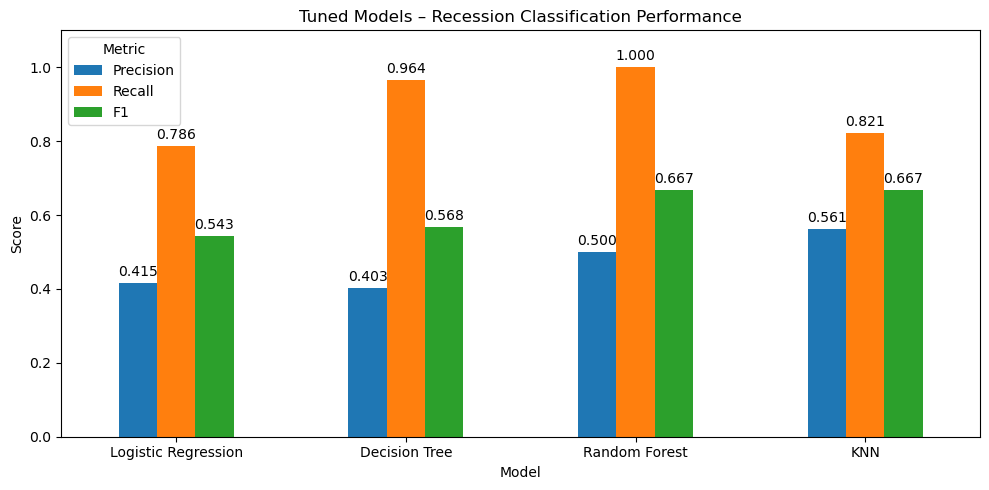

In [2213]:
# Compare tuned model performance
plot_data = tuned_test_comparison.set_index("Model")[
    ["Precision", "Recall", "F1"]
]

# Create bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

# Display values above each bar
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)

plt.title("Tuned Models – Recession Classification Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.1)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

### Permutation Feature Importance

Permutation importance measures how much a model's F1-score decreases when a feature's values are randomly shuffled. This helps identify which features are important for classification. The tuned Logistic Regression and Random Forest models were compared using the testing data.

In [2214]:
logistic_importance = permutation_importance(
    logistic_grid.best_estimator_,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

# Create a table of feature importance
importance_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": logistic_importance.importances_mean
})

# Sort from most important to least important
importance_table = importance_table.sort_values(
    "Importance", ascending=False
)

display(importance_table.round(3))

,Feature,Importance
1,SP500_12M_Return,0.273
11,GDP_Growth_YoY,0.032
14,Disposable_Income_Growth_YoY,0.028
12,Real_GDP_Per_Capita_Growth_YoY,0.028
5,Unemployment_Change_12M,0.021
0,SP500_Monthly_Return,0.017
9,Treasury_10Y_Change_12M,0.012
6,Federal_Funds_Rate,0.011
4,Unemployment_Rate,0.007
2,SP500_Volatility_6M,0.005


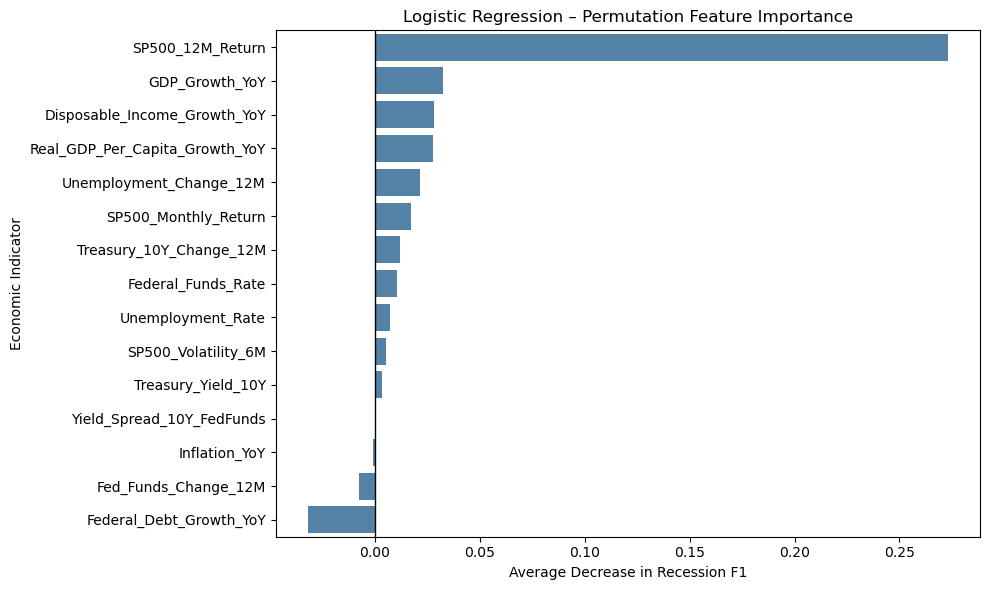

In [2215]:
# Plot Logistic Regression feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_table,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression – Permutation Feature Importance")
plt.xlabel("Average Decrease in Recession F1")
plt.ylabel("Economic Indicator")

plt.tight_layout()
plt.show()

In [2216]:
# Random Forest permutation importance
forest_importance = permutation_importance(
    forest_grid.best_estimator_,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

# Create and sort the importance table
forest_importance_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": forest_importance.importances_mean
})

forest_importance_table = forest_importance_table.sort_values(
    "Importance", ascending=False
)

display(forest_importance_table.round(3))

,Feature,Importance
12,Real_GDP_Per_Capita_Growth_YoY,0.298
1,SP500_12M_Return,0.015
5,Unemployment_Change_12M,0.004
14,Disposable_Income_Growth_YoY,0.004
3,Inflation_YoY,0.002
9,Treasury_10Y_Change_12M,0.002
6,Federal_Funds_Rate,0.001
0,SP500_Monthly_Return,0.000
4,Unemployment_Rate,0.000
7,Fed_Funds_Change_12M,0.000


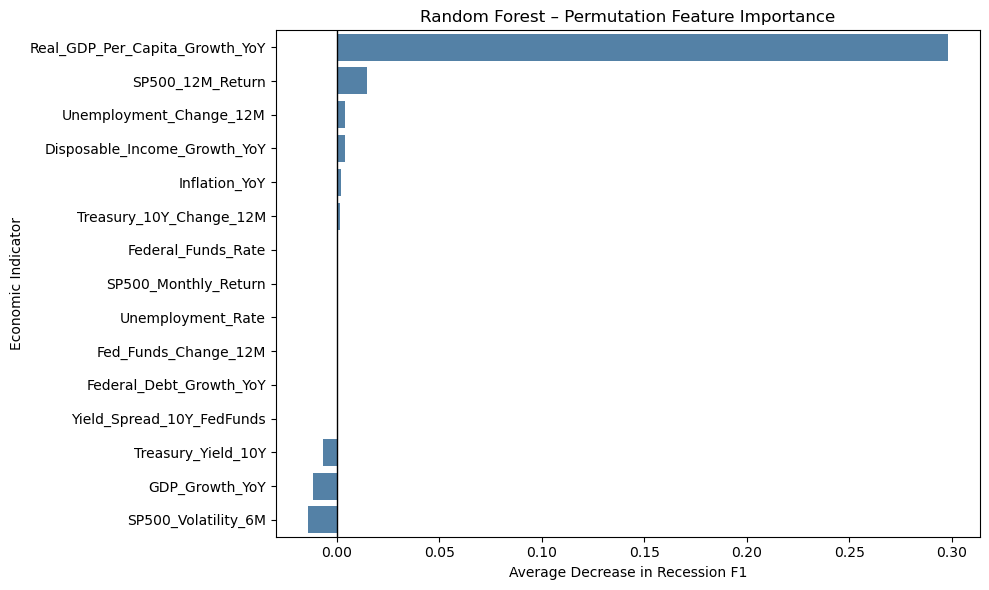

In [2217]:
# Plot Random Forest permutation importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=forest_importance_table,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Random Forest – Permutation Feature Importance")
plt.xlabel("Average Decrease in Recession F1")
plt.ylabel("Economic Indicator")

plt.tight_layout()
plt.show()

### Permutation Feature Importance - Key Findings

The two models relied on different indicators when classifying recession months.

**Logistic Regression:**
- S&P 500 12-month return had the highest importance (0.273).
- GDP growth (0.032), disposable income growth (0.028), and real GDP per capita growth (0.028) had smaller contributions.

**Random Forest:**
- Real GDP per capita growth had the highest importance (0.298).
- S&P 500 12-month return had a much smaller contribution (0.015).

Logistic Regression relied more heavily on annual stock market returns, while Random Forest placed greater importance on real GDP per capita growth.

## 19. Historical Evaluation of Recession Classification

The tuned Random Forest and KNN classifications were compared with actual NBER recession months during 2000–2026 to evaluate model performance during major recessions and identify periods with false recession classifications or missed recession months.

In [2218]:
# Compare actual, Random Forest, and KNN recession classifications
recession_results = test_data[["Date"]].copy()

recession_results["Actual"] = y_test.to_numpy()
recession_results["Random Forest"] = forest_grid.predict(X_test)
recession_results["KNN"] = knn_grid.predict(X_test)

# Count actual and predicted recession months by year
recession_results["Year"] = recession_results["Date"].dt.year

yearly_models = recession_results.groupby("Year")[
    ["Actual", "Random Forest", "KNN"]
].sum()

display(yearly_models)

,Actual,Random Forest,KNN
Year,,,
2000,0,0,0
2001,8,9,7
2002,0,6,6
2003,0,3,3
2004,0,0,0
2005,0,0,0
2006,0,0,0
2007,0,0,0
2008,12,12,11


### Historical Recession Classification - Model Comparison

Random Forest and KNN achieved the same testing F1-score (0.667), but showed different classification results.

**Random Forest:**
- Correctly identified all 28 recession months, achieving 100% recall.
- Generated additional recession classifications, particularly during recovery periods.

**KNN:**
- Achieved higher accuracy (92.8%) and precision (56.1%).
- Missed five recession months but generated fewer false positives.

Both models classified several months in 2002–2003 as recessions, even though those years were outside official NBER recession periods. Random Forest was better at identifying all recession months, while KNN produced fewer false recession alerts.

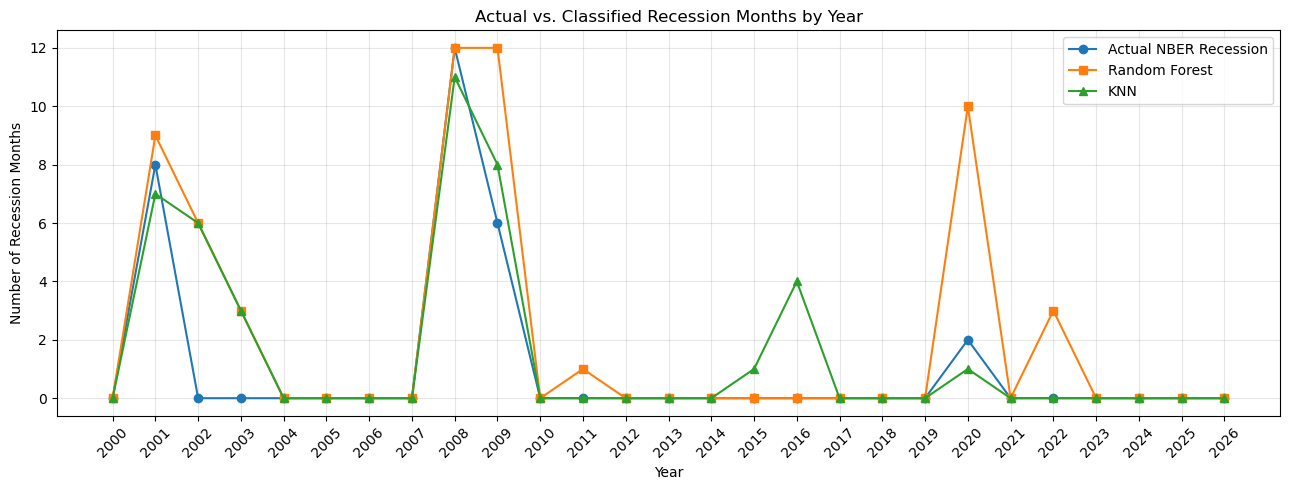

In [2219]:
# Plot actual vs. predicted recession months by year
plt.figure(figsize=(13, 5))

plt.plot(
    yearly_models.index,
    yearly_models["Actual"],
    marker="o",
    label="Actual NBER Recession"
)

plt.plot(
    yearly_models.index,
    yearly_models["Random Forest"],
    marker="s",
    label="Random Forest"
)

plt.plot(
    yearly_models.index,
    yearly_models["KNN"],
    marker="^",
    label="KNN"
)

plt.title("Actual vs. Classified Recession Months by Year")
plt.xlabel("Year")
plt.ylabel("Number of Recession Months")
plt.xticks(yearly_models.index, rotation=45)
plt.yticks(range(0, 13, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart for README
plt.savefig("images/recession_classification.png", dpi=300, bbox_inches="tight")

plt.show()

### Historical Recession Classification Key Findings

Both models identified recession conditions during the 2001 and 2008–2009 recessions. However, Random Forest also classified additional months during the subsequent recovery periods as recessionary.

The largest difference occurred in 2020:
- NBER identified 2 recession months.
- Random Forest classified 10 months as recessionary.
- KNN classified 1 month as recessionary.

Both models also generated false recession classifications during 2002–2003. Random Forest achieved higher recall, while KNN generated fewer false positives. However, KNN missed both actual recession months in March and April 2020 and incorrectly classified one other month that year as recessionary.

## 20. Part A: Final Results and Limitations

### I. Unsupervised Learning Findings

Three clustering methods were evaluated. K-Means provided the clearest economic interpretation with five clusters. GMM identified more detailed but overlapping patterns, while DBSCAN was more useful for detecting unusual observations than defining balanced economic regimes.

### II. Supervised Recession Classification Findings

Four supervised models were evaluated using NBER recession labels: Logistic Regression, Decision Tree, Random Forest, and KNN. The models were trained on 1960–1999 data and evaluated on the 2000–2026 test period. Time-series cross-validation was used for model selection and hyperparameter tuning.

**Key Findings:**

- Logistic Regression achieved the highest tuned cross-validation F1-score (0.533).
- Random Forest and KNN achieved the highest test F1-score (0.667).
- Random Forest identified all 28 recession months in the test period (100% recall), but generated more false positives.
- KNN achieved higher test precision (56.1%) and accuracy (92.8%), but missed five recession months.

Adding two nonlinear interaction features did not improve cross-validation performance.

**Feature Importance:**

Logistic Regression relied most heavily on the S&P 500's 12-month return, while Random Forest placed the greatest importance on real GDP per capita growth.

**Summary:**

Logistic Regression performed best during chronological cross-validation, while Random Forest and KNN performed best on the test period. They also highlight the trade-off between identifying recession months and avoiding false recession classifications.

### III. Limitations of the Study

The following limitations should be considered:

**1. Recession Classification vs. Forecasting**

The supervised models classify recession months using economic indicators from the same period. The results do not demonstrate the ability to predict recessions in advance.

**2. Class Imbalance**

Recession months represent a small portion of the dataset. For this reason, precision, recall, and F1-score are more informative than accuracy alone.

**3. Model Generalization**

Economic relationships can change over time. Differences between cross-validation and test performance suggest that models may not perform consistently across different economic periods.

**4. Correlated Economic Indicators**

Several features contain overlapping information, which can make individual feature contributions difficult to interpret.

**5. Clustering Limitations**

The clusters represent statistical patterns rather than formally defined economic regimes. Their number and interpretation depend on the methods and parameters selected.

Therefore, the findings are more useful for understanding historical economic conditions than for making reliable predictions about future recessions.

### IV. Financial Analyst and Portfolio Management Applications

The framework is intended to support analysis and risk monitoring rather than generate direct investment or trading signals.

| Potential Application | How the Analysis Can Help |
|---|---|
| Economic Regime Monitoring | Identify historical patterns in growth, inflation, unemployment, and market performance. |
| Inflation and Interest Rate Risk | Assess economic conditions related to equity and fixed-income risks. |
| Market Stress Analysis | Study historical periods of economic and financial stress. |
| Recession Risk Monitoring | Use recession classification results as supplementary indicators of economic conditions. |

## 21. Part B: S&P 500 Return Forecasting Setup

In Part B, historical economic and financial indicators were used to predict the following month's S&P 500 return. The target variable was created by shifting monthly returns one month forward. This allows the model to use information from the current month to predict the next month's return.

In [2220]:
# Sort the data by date
forecast_data = ml_data.sort_values("Date").copy()

# Create next month's S&P 500 return as the target
forecast_data["Next_Month_Return"] = forecast_data["SP500_Monthly_Return"].shift(-1)

# View the current and next month's returns
forecast_data[["Date", "SP500_Monthly_Return", "Next_Month_Return"]].head(10)

,Date,SP500_Monthly_Return,Next_Month_Return
0,1960-01-01,-1.743989,-3.877305
1,1960-02-01,-3.877305,-1.362496
2,1960-03-01,-1.362496,1.290440
3,1960-04-01,1.290440,-0.915127
4,1960-05-01,-0.915127,3.694314
5,1960-06-01,3.694314,-2.479916
6,1960-07-01,-2.479916,1.199857
7,1960-08-01,1.199857,-3.008317
8,1960-09-01,-3.008317,-1.970443
9,1960-10-01,-1.970443,3.238414


In [2221]:
# Check the date range and number of observations
print("First date:", forecast_data["Date"].min())
print("Last date:", forecast_data["Date"].max())
print("Total observations:", len(forecast_data))

# Check missing future returns
print("Missing targets:", forecast_data["Next_Month_Return"].isna().sum())

# Check training and test periods
print(forecast_data.groupby("Dataset")["Date"].agg(["min", "max", "count"]))

# Check for missing months
expected_months = pd.date_range(
    start=forecast_data["Date"].min(),
    end=forecast_data["Date"].max(),
    freq="MS"
)

print("Missing months:", len(expected_months.difference(forecast_data["Date"])))

First date: 1960-01-01 00:00:00
Last date: 2026-06-01 00:00:00
Total observations: 798
Missing targets: 1
               min        max  count
Dataset                             
Test    2000-01-01 2026-06-01    318
Train   1960-01-01 1999-12-01    480
Missing months: 0


In [2222]:
# Remove rows without a next-month return
forecast_data = forecast_data.dropna(subset=["Next_Month_Return"]).copy()

# Check the remaining observations
print("Total observations:", len(forecast_data))

print("\nTraining and test periods:")
print(
    forecast_data.groupby("Dataset")["Date"]
    .agg(["min", "max", "count"])
)

Total observations: 797

Training and test periods:
               min        max  count
Dataset                             
Test    2000-01-01 2026-05-01    317
Train   1960-01-01 1999-12-01    480


In [2223]:
# Create a separate forecasting dataset
forecast_ready = forecast_data.copy()

# Use previous-month inflation and unemployment information
forecast_ready["Inflation_Lag1"] = forecast_ready["Inflation_YoY"].shift(1)
forecast_ready["Unemployment_Lag1"] = forecast_ready["Unemployment_Rate"].shift(1)
forecast_ready["Unemployment_Change_Lag1"] = forecast_ready["Unemployment_Change_12M"].shift(1)

# Check the new features
forecast_ready[[
    "Date",
    "Inflation_YoY",
    "Inflation_Lag1",
    "Unemployment_Rate",
    "Unemployment_Lag1"
]].head(10)

,Date,Inflation_YoY,Inflation_Lag1,Unemployment_Rate,Unemployment_Lag1
0,1960-01-01,1.240951,NaN,5.2,NaN
1,1960-02-01,1.413793,1.240951,4.8,5.2
2,1960-03-01,1.518813,1.413793,5.4,4.8
3,1960-04-01,1.932367,1.518813,5.2,5.4
4,1960-05-01,1.825069,1.932367,5.1,5.2
5,1960-06-01,1.717623,1.825069,5.4,5.1
6,1960-07-01,1.372213,1.717623,5.5,5.4
7,1960-08-01,1.473612,1.372213,5.6,5.5
8,1960-09-01,1.230769,1.473612,5.5,5.6
9,1960-10-01,1.362862,1.230769,6.1,5.5


In [2224]:
# Use economic data from 3 months earlier
forecast_ready["GDP_Lag3"] = forecast_ready["GDP_Growth_YoY"].shift(3)

forecast_ready["Real_GDP_Per_Capita_Lag3"] = (
    forecast_ready["Real_GDP_Per_Capita_Growth_YoY"].shift(3)
)

forecast_ready["Federal_Debt_Lag3"] = (
    forecast_ready["Federal_Debt_Growth_YoY"].shift(3)
)

forecast_ready["Disposable_Income_Lag3"] = (
    forecast_ready["Disposable_Income_Growth_YoY"].shift(3)
)

# Check the results
forecast_ready[[
    "Date",
    "GDP_Growth_YoY",
    "GDP_Lag3",
    "Real_GDP_Per_Capita_Lag3",
    "Federal_Debt_Lag3",
    "Disposable_Income_Lag3"
]].head(8)


,Date,GDP_Growth_YoY,GDP_Lag3,Real_GDP_Per_Capita_Lag3,Federal_Debt_Lag3,Disposable_Income_Lag3
0,1960-01-01,6.332765,NaN,NaN,NaN,NaN
1,1960-02-01,6.332765,NaN,NaN,NaN,NaN
2,1960-03-01,6.332765,NaN,NaN,NaN,NaN
3,1960-04-01,3.525666,6.332765,3.009296,0.694191,1.933869
4,1960-05-01,3.525666,6.332765,3.009296,0.656216,1.544402
5,1960-06-01,3.525666,6.332765,3.009296,2.481481,1.002487
6,1960-07-01,3.917842,3.525666,-0.015468,1.875690,0.667367
7,1960-08-01,3.917842,3.525666,-0.015468,2.240176,0.276284


In [2225]:
# Combine lagged inflation with the Federal Funds Rate
forecast_ready["Inflation_FedFunds_Forecast"] = (
    forecast_ready["Inflation_Lag1"] *
    forecast_ready["Federal_Funds_Rate"]
)

# Combine the yield spread with lagged unemployment
forecast_ready["YieldSpread_Unemployment_Forecast"] = (
    forecast_ready["Yield_Spread_10Y_FedFunds"] *
    forecast_ready["Unemployment_Lag1"]
)

# Check the new interaction features
forecast_ready[[
    "Date",
    "Inflation_FedFunds_Forecast",
    "YieldSpread_Unemployment_Forecast"
]].head(8)

,Date,Inflation_FedFunds_Forecast,YieldSpread_Unemployment_Forecast
0,1960-01-01,NaN,NaN
1,1960-02-01,4.926577,2.704
2,1960-03-01,5.428966,1.968
3,1960-04-01,5.953745,1.944
4,1960-05-01,7.439614,2.600
5,1960-06-01,6.059229,4.233
6,1960-07-01,5.547922,3.618
7,1960-08-01,4.089194,4.510


In [2226]:
# Final features for predicting next month's S&P 500 return
forecast_features = [
    "SP500_Monthly_Return",
    "SP500_12M_Return",
    "SP500_Volatility_6M",
    "Federal_Funds_Rate",
    "Fed_Funds_Change_12M",
    "Treasury_Yield_10Y",
    "Treasury_10Y_Change_12M",
    "Yield_Spread_10Y_FedFunds",
    "Inflation_Lag1",
    "Unemployment_Lag1",
    "Unemployment_Change_Lag1",
    "GDP_Lag3",
    "Real_GDP_Per_Capita_Lag3",
    "Federal_Debt_Lag3",
    "Disposable_Income_Lag3",
    "Inflation_FedFunds_Forecast",
    "YieldSpread_Unemployment_Forecast"
]

# Keep only rows with all forecasting features available
forecast_ready = forecast_ready.dropna(
    subset=forecast_features + ["Next_Month_Return"]
).copy()

# Create the final training and test datasets
forecast_train = forecast_ready[
    forecast_ready["Dataset"] == "Train"
].copy()

forecast_test = forecast_ready[
    forecast_ready["Dataset"] == "Test"
].copy()

# Prevent training targets from overlapping the test period
first_test_date = forecast_test["Date"].min()

forecast_train = forecast_train[
    forecast_train["Date"] + pd.DateOffset(months=1) < first_test_date
].copy()

# Check the final datasets
print("Training observations:", len(forecast_train))
print("Test observations:", len(forecast_test))
print("Last training target date:",
      forecast_train["Date"].max() + pd.DateOffset(months=1))
print("First test predictor date:", first_test_date)

Training observations: 476
Test observations: 317
Last training target date: 1999-12-01 00:00:00
First test predictor date: 2000-01-01 00:00:00


### Final Forecasting Features

A total of 17 economic and financial features were selected to predict the following month's S&P 500 return. Some indicators were lagged by one or three months. Observations with missing forecasting features were removed, while the chronological training and testing periods were maintained.

The final dataset contains:

- **476 training observations:** April 1960 – November 1999
- **317 test observations:** January 2000 – May 2026

These features will be used to predict the following month's S&P 500 return.

## 22. Baseline and Regression Models

This section evaluates Ridge Regression to predict next-month S&P 500 returns using the 17 forecasting features. Ridge Regression applies L2 regularization, which helps reduce overfitting and manage correlated features.

Three models were compared using Mean Absolute Error (MAE) and R²:

- Historical mean baseline
- Ridge Regression with alpha = 1
- Tuned Ridge Regression

In [2227]:
# Prepare predictors
X_train = forecast_train[forecast_features]
X_test = forecast_test[forecast_features]

# Prepare target
y_train = forecast_train["Next_Month_Return"]
y_test = forecast_test["Next_Month_Return"]

# Check the dataset sizes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (476, 17)
X_test: (317, 17)
y_train: (476,)
y_test: (317,)


### Historical Mean Baseline

The average monthly S&P 500 return from the training period was used as a baseline prediction. This provides a simple reference to evaluate whether Ridge Regression improves forecasting accuracy.

In [2228]:
# Train the baseline model
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

# Predict next month's returns
baseline_pred = baseline_model.predict(X_test)

# Calculate forecasting errors
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 2.658
Baseline RMSE: 3.711


In [2229]:
# Build and train Ridge Regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)

# Predict next month's S&P 500 returns
ridge_pred = ridge_model.predict(X_test)

# Calculate forecasting errors
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

print("Ridge Regression MAE:", round(ridge_mae, 3))
print("Ridge Regression RMSE:", round(ridge_rmse, 3))

Ridge Regression MAE: 2.832
Ridge Regression RMSE: 3.916


In [2230]:
# Define chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Try different regularization strengths
ridge_params = {
    "ridge__alpha": [0.1, 1, 10, 100, 1000, 10000]
}

# Tune Ridge Regression using training data only
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    ridge_params,
    cv=tscv,
    scoring="neg_mean_absolute_error"
)

ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_["ridge__alpha"])
print("Cross-validation MAE:", round(-ridge_search.best_score_, 3))

Best alpha: 1000
Cross-validation MAE: 2.59


In [2231]:
# Get the best Ridge model
tuned_ridge = ridge_search.best_estimator_

# Predict test-period returns
tuned_ridge_pred = tuned_ridge.predict(X_test)

# Calculate test errors
tuned_ridge_mae = mean_absolute_error(y_test, tuned_ridge_pred)
tuned_ridge_rmse = np.sqrt(mean_squared_error(y_test, tuned_ridge_pred))

print("Tuned Ridge MAE:", round(tuned_ridge_mae, 3))
print("Tuned Ridge RMSE:", round(tuned_ridge_rmse, 3))


Tuned Ridge MAE: 2.591
Tuned Ridge RMSE: 3.7


In [2232]:
# Calculate R² for each model
baseline_r2 = r2_score(y_test, baseline_pred)
ridge_r2 = r2_score(y_test, ridge_pred)
tuned_ridge_r2 = r2_score(y_test, tuned_ridge_pred)

print("Baseline R²:", round(baseline_r2, 3))
print("Ridge R²:", round(ridge_r2, 3))
print("Tuned Ridge R²:", round(tuned_ridge_r2, 3))

Baseline R²: -0.002
Ridge R²: -0.115
Tuned Ridge R²: 0.005


In [2233]:
# Compare baseline and Ridge Regression performance
model_comparison = pd.DataFrame({
    "Model": [
        "Historical Mean Baseline",
        "Ridge Regression",
        "Tuned Ridge Regression"
    ],
    "MAE": [
        baseline_mae,
        ridge_mae,
        tuned_ridge_mae
    ],
    "R2": [
        baseline_r2,
        ridge_r2,
        tuned_ridge_r2
    ]
})

display(model_comparison.round(3))

,Model,MAE,R2
0,Historical Mean Baseline,2.658,-0.002
1,Ridge Regression,2.832,-0.115
2,Tuned Ridge Regression,2.591,0.005


### Ridge Regression Results and Interpretation

Five-fold time-series cross-validation was used to tune Ridge Regression. The best alpha was 1,000, with a cross-validation MAE of 2.590.

On the test data:

- **Historical Mean Baseline:** MAE = 2.658, R² = -0.002
- **Ridge Regression:** MAE = 2.832, R² = -0.115
- **Tuned Ridge Regression:** MAE = 2.591, R² = 0.005

The untuned Ridge model performed worse than the baseline. After tuning, Ridge Regression achieved a slightly lower MAE, improving on the baseline by approximately 2.5%. However, the tuned model's R² of 0.005 indicates that it explained only about 0.5% of the variation in monthly returns.

Although some economic indicators were lagged to approximate reporting delays, historical data revisions and differences in publication timing may limit real-time forecasting performance. Ridge Regression provided only a modest improvement over the historical mean baseline. The results suggest that predicting next-month S&P 500 returns remains challenging.

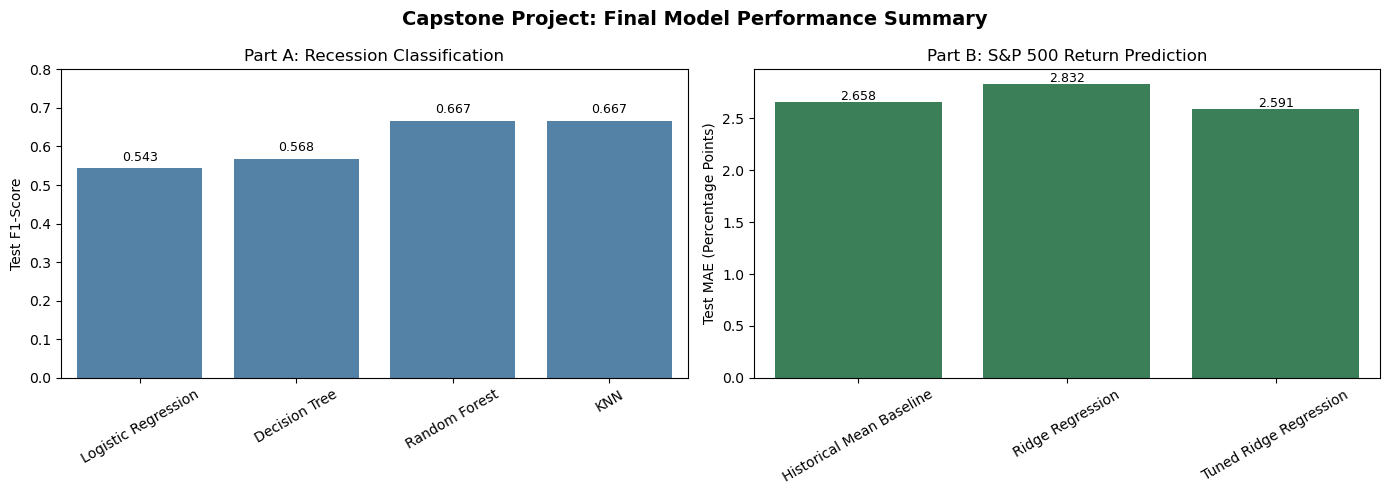

In [2234]:
# Final visualization: Part A and Part B model performance

# Prepare Part A results
part_a = tuned_test_comparison.copy()

# Prepare Part B results
part_b = model_comparison.copy()

# Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Part A: Recession classification
sns.barplot(
    data=part_a,
    x="Model",
    y="F1",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Part A: Recession Classification")
axes[0].set_ylabel("Test F1-Score")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 0.8)
axes[0].tick_params(axis="x", rotation=30)

# Part B: S&P 500 return prediction
sns.barplot(
    data=part_b,
    x="Model",
    y="MAE",
    ax=axes[1],
    color="seagreen"
)

axes[1].set_title("Part B: S&P 500 Return Prediction")
axes[1].set_ylabel("Test MAE (Percentage Points)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)

# Add values above the bars
for ax in axes:
    for bar in ax.patches:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            f"{height:.3f}",
            ha="center",
            fontsize=9
        )

plt.suptitle("Capstone Project: Final Model Performance Summary",
             fontsize=14, fontweight="bold")

plt.tight_layout()

# Save chart for README
plt.savefig("images/final_model_performance.png", dpi=300, bbox_inches="tight")

plt.show()

# Final Conclusion

This capstone project explored how machine learning can be used to identify U.S. economic and financial market regimes, classify historical recessions, and predict S&P 500 returns.

**Part A: Economic Regime Identification and Recession Classification**

K-Means, GMM, and DBSCAN identified different patterns in economic conditions. K-Means provided the clearest economic interpretation through five clusters.

For supervised recession classification, Logistic Regression achieved the highest cross-validation F1-score (0.533), while Random Forest and KNN achieved the highest test F1-score (0.667).

**Part B: S&P 500 Return Prediction**

Tuned Ridge Regression achieved a test MAE of 2.591 and an R² of 0.005. Although it slightly outperformed the historical mean baseline, its predictive performance remained limited.

**Conclusion**

Predicting short-term stock market returns remains difficult. The findings may support economic research, financial analysis, and portfolio risk assessment. The models are best used as supplementary analytical tools rather than standalone forecasting or investment decision-making systems.